In [3]:
import xarray as xr

evt_file = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

ds = xr.open_dataset(
    evt_file,
    decode_timedelta=False
)

print("Dimensions:", ds.sizes)
print("Variables:", list(ds.data_vars))

print("\nHeatwave duration:")
print(ds["hw_duration"].dims, ds["hw_duration"].shape)

print("\nFlash drought duration:")
print(ds["fd_duration"].dims, ds["fd_duration"].shape)



Dimensions: Frozen({'harvest_year': 44, 'latitude': 57, 'longitude': 89})
Variables: ['hw_duration', 'fd_duration']

Heatwave duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)

Flash drought duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)


In [5]:
import xarray as xr

evt_file = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

ds = xr.open_dataset(
    evt_file,
    decode_timedelta=False
)

# =========================================================
# DATASET INSPECTION
# =========================================================

print("Dimensions:", ds.sizes)
print("Variables:", list(ds.data_vars))

# =========================================================
# HEATWAVE
# =========================================================

print("\nHeatwave duration:")
print(ds["hw_duration"].dims, ds["hw_duration"].shape)

# =========================================================
# FLASH DROUGHT
# =========================================================

print("\nFlash drought duration:")
print(ds["fd_duration"].dims, ds["fd_duration"].shape)

# =========================================================
# COMPOUND EVENT VARIABLES
# =========================================================

print("\nCompound event variables:")

compound_vars = [
    var for var in ds.data_vars
    if any(term in var.lower() for term in ["compound", "simultaneous", "severity"])
]

for var in compound_vars:
    print(f"{var}:")
    print("   dimensions:", ds[var].dims)
    print("   shape:", ds[var].shape)

Dimensions: Frozen({'harvest_year': 44, 'latitude': 57, 'longitude': 89})
Variables: ['hw_duration', 'fd_duration']

Heatwave duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)

Flash drought duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)

Compound event variables:


In [16]:
import xarray as xr

# ---------------------------------------------------------
# LOAD EVENT DURATION DATA
# ---------------------------------------------------------

# Heatwave and flash-drought event inputs
evt_file = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

ds_evt = xr.open_dataset(
    evt_file,
    decode_timedelta=False
)

# CDHW event duration
cdhw_file = r"C:\Users\franc\cdhw_severity_1982_2025.nc"

ds_cdhw = xr.open_dataset(
    cdhw_file,
    decode_timedelta=False
)

# ---------------------------------------------------------
# CHECK DATASETS
# ---------------------------------------------------------

print("========================================")
print("HEATWAVE + FLASH DROUGHT DATASET")
print("========================================")

print("Dimensions:", ds_evt.sizes)
print("Variables:", list(ds_evt.data_vars))

print("\nHeatwave duration:")
print(ds_evt["hw_duration"].dims, ds_evt["hw_duration"].shape)

print("\nFlash drought duration:")
print(ds_evt["fd_duration"].dims, ds_evt["fd_duration"].shape)


print("\n========================================")
print("CDHW DATASET")
print("========================================")

print("Dimensions:", ds_cdhw.sizes)
print("Variables:", list(ds_cdhw.data_vars))

print("\nCDHW variables:")
for var in ds_cdhw.data_vars:
    print(f"{var}: {ds_cdhw[var].dims}, {ds_cdhw[var].shape}")

HEATWAVE + FLASH DROUGHT DATASET
Dimensions: Frozen({'harvest_year': 44, 'latitude': 57, 'longitude': 89})
Variables: ['hw_duration', 'fd_duration']

Heatwave duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)

Flash drought duration:
('harvest_year', 'latitude', 'longitude') (44, 57, 89)

CDHW DATASET
Dimensions: Frozen({'harvest_year': 44, 'latitude': 57, 'longitude': 89})
Variables: ['cdhw_simultaneous_days', 'cdhw_heat_intensity', 'cdhw_drought_intensity', 'cdhw_cumulative_severity', 'cdhw_peak_severity', 'cdhw_mean_severity']

CDHW variables:
cdhw_simultaneous_days: ('harvest_year', 'latitude', 'longitude'), (44, 57, 89)
cdhw_heat_intensity: ('harvest_year', 'latitude', 'longitude'), (44, 57, 89)
cdhw_drought_intensity: ('harvest_year', 'latitude', 'longitude'), (44, 57, 89)
cdhw_cumulative_severity: ('harvest_year', 'latitude', 'longitude'), (44, 57, 89)
cdhw_peak_severity: ('harvest_year', 'latitude', 'longitude'), (44, 57, 89)
cdhw_mean_severity: ('harvest_year', 

In [4]:
import numpy as np
import scipy.stats as stats
import xarray as xr


def fit_gev(x, include_zeros=False, min_n=10):

    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    n_all = x.size

    if n_all == 0:
        return (np.nan,) * 3 + (np.nan, 0)

    if include_zeros:
        sample = x
        lam = 1.0

    else:
        sample = x[x > 0]
        lam = sample.size / n_all if n_all else np.nan

    if sample.size < min_n or np.allclose(sample, sample[0]):
        return (np.nan,) * 3 + (lam, sample.size)

    c, loc, scale = stats.genextreme.fit(sample)

    xi = -c

    return loc, scale, xi, lam, sample.size


def return_level(T, mu, sigma, xi, lam=1.0):

    T = np.asarray(T, dtype=float)

    if not np.isfinite([mu, sigma, xi]).all():
        return np.full(T.shape, np.nan)

    p = 1.0 / (lam * T)

    p = np.clip(
        p,
        1e-12,
        1 - 1e-12
    )

    y = -np.log(1.0 - p)

    if abs(xi) < 1e-8:
        return mu - sigma * np.log(y)

    return mu - (
        sigma / xi
    ) * (
        1.0 - y ** (-xi)
    )


def _grid_kernel(
    series,
    periods,
    include_zeros,
    min_n
):

    mu, sig, xi, lam, m = fit_gev(
        series,
        include_zeros=include_zeros,
        min_n=min_n
    )

    if not np.isfinite([mu, sig, xi]).all():
        return (
            np.full(len(periods), np.nan),
            np.nan,
            np.nan
        )

    return (
        return_level(
            np.asarray(periods, float),
            mu,
            sig,
            xi,
            lam
        ),
        xi,
        lam
    )


def return_levels_grid(
    da,
    periods,
    time_dim="harvest_year",
    include_zeros=False,
    min_n=10
):

    periods = np.asarray(
        periods,
        dtype=float
    )

    rl, xi, lam = xr.apply_ufunc(
        _grid_kernel,
        da,
        kwargs={
            "periods": periods,
            "include_zeros": include_zeros,
            "min_n": min_n
        },
        input_core_dims=[
            [time_dim]
        ],
        output_core_dims=[
            ["return_period"],
            [],
            []
        ],
        vectorize=True,
        output_dtypes=[
            float,
            float,
            float
        ],
        dask_gufunc_kwargs={
            "output_sizes": {
                "return_period":
                periods.size
            }
        }
    )

    rl = rl.assign_coords(
        return_period=periods
    )

    spatial = [
        d for d in da.dims
        if d != time_dim
    ]

    rl = rl.transpose(
        "return_period",
        *spatial
    )

    out = xr.Dataset({
        "return_level": rl,
        "gev_shape": xi,
        "occurrence_rate": lam
    })

    out["return_period"].attrs["units"] = "years"

    return out

In [3]:
periods = [20, 50, 100]

hw_duration_rl = return_levels_grid(
    ds["hw_duration"],
    periods=periods,
    time_dim="harvest_year",
    include_zeros=False,
    min_n=10
)

print("Heatwave duration return levels completed.")

for T in periods:

    values = hw_duration_rl[
        "return_level"
    ].sel(
        return_period=T
    ).values

    print(
        f"{T}-year:",
        "median =",
        np.nanmedian(values),
        "min =",
        np.nanmin(values),
        "max =",
        np.nanmax(values)
    )

Heatwave duration return levels completed.
20-year: median = 45.02217009901526 min = 3.0 max = 3.254551849998587e+17
50-year: median = 74.81571608070092 min = 3.0 max = 1.7960659105509106e+23
100-year: median = 109.0787349850957 min = 3.0 max = 3.551151478391171e+27


In [4]:
hw_duration_output = (
    r"C:\Users\franc"
    r"\hw_duration_return_levels_20_50_100yr.nc"
)

hw_duration_rl[
    "return_level"
].attrs.update(
    long_name="Heatwave duration return level",
    units="days",
    description=(
        "Heatwave duration expected to be "
        "exceeded on average once every "
        "specified return period."
    )
)

hw_duration_rl.to_netcdf(
    hw_duration_output
)

print("Saved:")
print(hw_duration_output)

Saved:
C:\Users\franc\hw_duration_return_levels_20_50_100yr.nc


In [5]:
fd_duration_rl = return_levels_grid(
    ds["fd_duration"],
    periods=periods,
    time_dim="harvest_year",
    include_zeros=False,
    min_n=10
)

fd_duration_rl[
    "return_level"
].attrs.update(
    long_name="Flash drought duration return level",
    units="days",
    description=(
        "Flash drought duration expected "
        "to be exceeded on average once "
        "every specified return period."
    )
)

fd_duration_output = (
    r"C:\Users\franc"
    r"\fd_duration_return_levels_20_50_100yr.nc"
)

fd_duration_rl.to_netcdf(
    fd_duration_output
)

print("Flash drought duration return levels completed.")

for T in periods:

    values = fd_duration_rl[
        "return_level"
    ].sel(
        return_period=T
    ).values

    print(
        f"{T}-year:",
        "median =",
        np.nanmedian(values),
        "min =",
        np.nanmin(values),
        "max =",
        np.nanmax(values)
    )

print("\nSaved:")
print(fd_duration_output)

Flash drought duration return levels completed.
20-year: median = 126.42409717776277 min = 79.14812567774678 max = 364324681329.00507
50-year: median = 192.4957445415193 min = 99.68714744475977 max = 4305782446334507.0
100-year: median = 257.2148638515879 min = 104.94959074484066 max = 9.044530343380974e+18

Saved:
C:\Users\franc\fd_duration_return_levels_20_50_100yr.nc


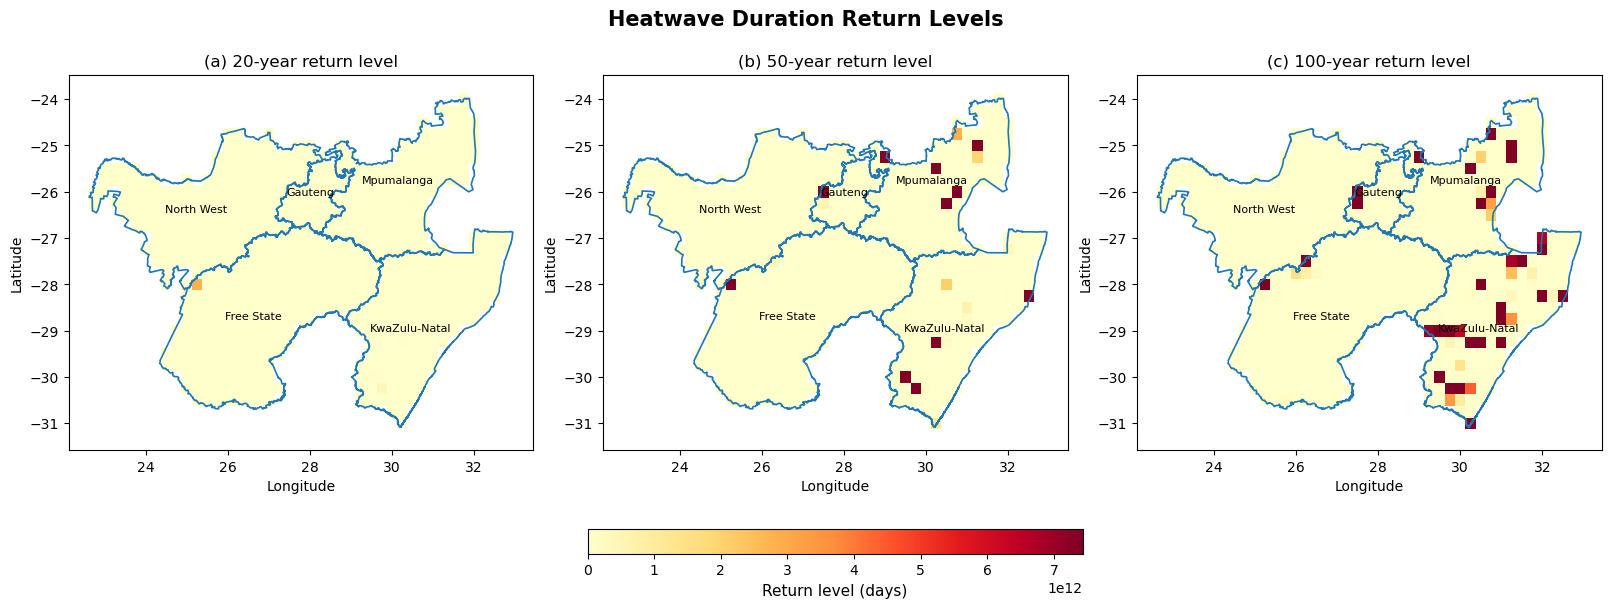

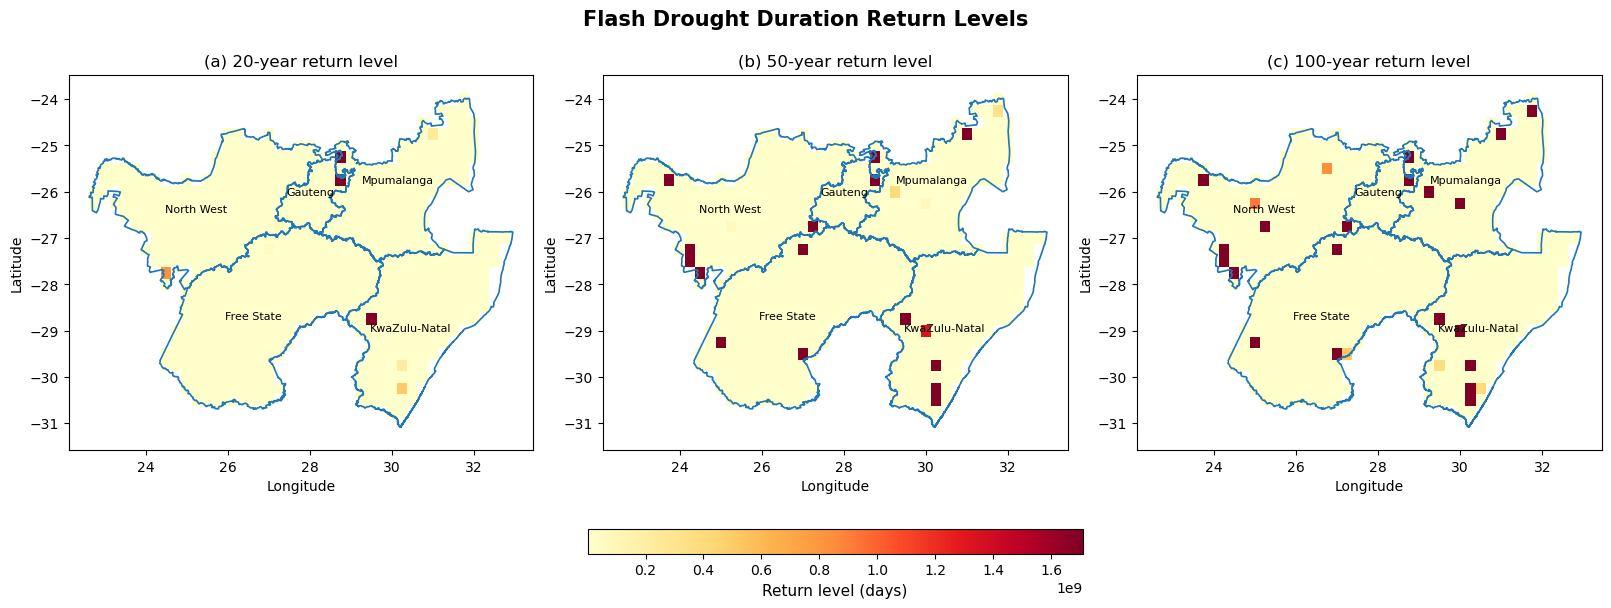

In [6]:
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from shapely.geometry import Point

# ------------------------------------------------------------
# FILES
# ------------------------------------------------------------
province_file = r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

hw_file = r"C:\Users\franc\hw_duration_return_levels_20_50_100yr.nc"
fd_file = r"C:\Users\franc\fd_duration_return_levels_20_50_100yr.nc"

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------
hw_rl = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

fd_rl = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

provinces = gpd.read_file(province_file)

if provinces.crs != "EPSG:4326":
    provinces = provinces.to_crs("EPSG:4326")

study_names = [
    "Mpumalanga",
    "North West",
    "Gauteng",
    "Free State",
    "KwaZulu-Natal"
]

study_provinces = provinces[
    provinces["ProvinceName"].isin(study_names)
].copy()

# ------------------------------------------------------------
# BUILD STUDY-AREA MASK
# ------------------------------------------------------------
try:
    study_geom = study_provinces.geometry.union_all()
except:
    study_geom = study_provinces.geometry.unary_union

lat = hw_rl.latitude.values
lon = hw_rl.longitude.values

mask = np.zeros(
    (len(lat), len(lon)),
    dtype=bool
)

for i, y in enumerate(lat):
    for j, x in enumerate(lon):
        mask[i, j] = study_geom.covers(
            Point(x, y)
        )

mask_da = xr.DataArray(
    mask,
    coords={
        "latitude": lat,
        "longitude": lon
    },
    dims=[
        "latitude",
        "longitude"
    ]
)

# ------------------------------------------------------------
# PLOTTING FUNCTION
# ------------------------------------------------------------
def plot_duration_return_levels(ds, hazard_name, output_file):

    periods = [20, 50, 100]

    data_list = []

    for T in periods:
        da = ds["return_level"].sel(
            return_period=T
        ).where(mask_da)

        data_list.append(da)

    # common colour scale
    all_values = np.concatenate([
        da.values[np.isfinite(da.values)]
        for da in data_list
    ])

    vmin = np.nanpercentile(all_values, 2)
    vmax = np.nanpercentile(all_values, 98)

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 6),
        constrained_layout=True
    )

    labels = ["(a)", "(b)", "(c)"]

    bounds = study_provinces.total_bounds
    xmin, ymin, xmax, ymax = bounds

    pad_x = 0.5
    pad_y = 0.5

    im = None

    for ax, da, T, label in zip(
        axes,
        data_list,
        periods,
        labels
    ):

        im = da.plot(
            ax=ax,
            x="longitude",
            y="latitude",
            cmap="YlOrRd",
            vmin=vmin,
            vmax=vmax,
            add_colorbar=False
        )

        study_provinces.boundary.plot(
            ax=ax,
            linewidth=1.2
        )

        for _, row in study_provinces.iterrows():

            point = row.geometry.representative_point()

            ax.text(
                point.x,
                point.y,
                row["ProvinceName"],
                fontsize=8,
                ha="center",
                va="center"
            )

        ax.set_xlim(
            xmin - pad_x,
            xmax + pad_x
        )

        ax.set_ylim(
            ymin - pad_y,
            ymax + pad_y
        )

        ax.set_title(
            f"{label} {T}-year return level",
            fontsize=12
        )

        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    cbar = fig.colorbar(
        im,
        ax=axes,
        orientation="horizontal",
        fraction=0.06,
        pad=0.08
    )

    cbar.set_label(
        "Return level (days)",
        fontsize=11
    )

    fig.suptitle(
        f"{hazard_name} Duration Return Levels",
        fontsize=15,
        fontweight="bold"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# HEATWAVE
# ------------------------------------------------------------
plot_duration_return_levels(
    hw_rl,
    "Heatwave",
    r"C:\Users\franc\heatwave_duration_return_levels_20_50_100yr.png"
)

# ------------------------------------------------------------
# FLASH DROUGHT
# ------------------------------------------------------------
plot_duration_return_levels(
    fd_rl,
    "Flash Drought",
    r"C:\Users\franc\flash_drought_duration_return_levels_20_50_100yr.png"
)

In [18]:
print(hw_rl["return_level"].dtype)
print(fd_rl["return_level"].dtype)

for T in [20, 50, 100]:
    hw_vals = hw_rl["return_level"].sel(return_period=T).values
    fd_vals = fd_rl["return_level"].sel(return_period=T).values

    print(f"\n{T}-year Heatwave duration")
    print("min:", np.nanmin(hw_vals))
    print("median:", np.nanmedian(hw_vals))
    print("max:", np.nanmax(hw_vals))

    print(f"{T}-year Flash drought duration")
    print("min:", np.nanmin(fd_vals))
    print("median:", np.nanmedian(fd_vals))
    print("max:", np.nanmax(fd_vals))

NameError: name 'hw_rl' is not defined

In [19]:
# Close old datasets if they exist
try:
    hw_rl.close()
except:
    pass

try:
    fd_rl.close()
except:
    pass

# Remove them from memory
try:
    del hw_rl
    del fd_rl
except:
    pass

In [20]:
import xarray as xr

hw_file = r"C:\Users\franc\hw_duration_return_levels_20_50_100yr.nc"
fd_file = r"C:\Users\franc\fd_duration_return_levels_20_50_100yr.nc"

hw_rl = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

fd_rl = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

print("HW dtype:", hw_rl["return_level"].dtype)
print("FD dtype:", fd_rl["return_level"].dtype)

HW dtype: float64
FD dtype: float64


In [21]:
import numpy as np

for T in [20, 50, 100]:

    hw_vals = hw_rl["return_level"].sel(
        return_period=T
    ).values

    fd_vals = fd_rl["return_level"].sel(
        return_period=T
    ).values

    print(f"\n{T}-year HEATWAVE duration return level")
    print("min:", np.nanmin(hw_vals))
    print("median:", np.nanmedian(hw_vals))
    print("max:", np.nanmax(hw_vals))

    print(f"\n{T}-year FLASH DROUGHT duration return level")
    print("min:", np.nanmin(fd_vals))
    print("median:", np.nanmedian(fd_vals))
    print("max:", np.nanmax(fd_vals))


20-year HEATWAVE duration return level
min: 3.0
median: 45.02217009901526
max: 3.254551849998587e+17

20-year FLASH DROUGHT duration return level
min: 79.14812567774678
median: 126.42409717776277
max: 364324681329.00507

50-year HEATWAVE duration return level
min: 3.0
median: 74.81571608070092
max: 1.7960659105509106e+23

50-year FLASH DROUGHT duration return level
min: 99.68714744475977
median: 192.4957445415193
max: 4305782446334507.0

100-year HEATWAVE duration return level
min: 3.0
median: 109.0787349850957
max: 3.551151478391171e+27

100-year FLASH DROUGHT duration return level
min: 104.94959074484066
median: 257.2148638515879
max: 9.044530343380974e+18


In [22]:
# For frequency
import xarray as xr

hw_file = r"C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025_updated.nc"
fd_file = r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"

hw = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

fd = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

print("HEATWAVE VARIABLES")
for v in hw.data_vars:
    print(v, hw[v].dims, hw[v].attrs.get("units"))

print("\nFLASH DROUGHT VARIABLES")
for v in fd.data_vars:
    print(v, fd[v].dims, fd[v].attrs.get("units"))

HEATWAVE VARIABLES
hw_frequency ('harvest_year', 'latitude', 'longitude') None
hw_duration ('harvest_year', 'latitude', 'longitude') None
hw_intensity ('harvest_year', 'latitude', 'longitude') None

FLASH DROUGHT VARIABLES
fd_frequency ('harvest_year', 'lat', 'lon') None
fd_total_duration ('harvest_year', 'lat', 'lon') None
fd_max_duration ('harvest_year', 'lat', 'lon') None
fd_cumulative_intensity ('harvest_year', 'lat', 'lon') None
fd_peak_intensity ('harvest_year', 'lat', 'lon') None


In [23]:
# Rename flash-drought spatial dimensions
fd_freq = fd["fd_frequency"].rename({
    "lat": "latitude",
    "lon": "longitude"
})

hw_freq = hw["hw_frequency"]

print("HW frequency:", hw_freq.dims, hw_freq.shape)
print("FD frequency:", fd_freq.dims, fd_freq.shape)

HW frequency: ('harvest_year', 'latitude', 'longitude') (44, 57, 89)
FD frequency: ('harvest_year', 'latitude', 'longitude') (44, 141, 220)


In [24]:
fd_freq_rg = fd_freq.interp(
    latitude=hw_freq.latitude,
    longitude=hw_freq.longitude,
    method="nearest"
)

print("Regridded FD frequency:", fd_freq_rg.shape)

Regridded FD frequency: (44, 57, 89)


In [25]:
hw_freq, fd_freq_rg = xr.align(
    hw_freq,
    fd_freq_rg,
    join="inner"
)

print("Aligned HW:", hw_freq.shape)
print("Aligned FD:", fd_freq_rg.shape)
print("Years:", hw_freq.harvest_year.values[[0, -1]])

Aligned HW: (44, 57, 89)
Aligned FD: (44, 57, 89)
Years: [1982 2025]


In [ ]:
periods = [20, 50, 100]

hw_freq_rl = return_levels_grid(
    hw_freq,
    periods=periods,
    time_dim="harvest_year",
    include_zeros=False,
    min_n=10
)

fd_freq_rl = return_levels_grid(
    fd_freq_rg,
    periods=periods,
    time_dim="harvest_year",
    include_zeros=False,
    min_n=10
)

print("Frequency return levels calculated.")

In [16]:
hw_freq_rl["return_level"].attrs.update(
    long_name="Heatwave frequency return level",
    units="events per maize season"
)

fd_freq_rl["return_level"].attrs.update(
    long_name="Flash drought frequency return level",
    units="events per maize season"
)

hw_freq_out = r"C:\Users\franc\hw_frequency_return_levels_20_50_100yr.nc"
fd_freq_out = r"C:\Users\franc\fd_frequency_return_levels_20_50_100yr.nc"

hw_freq_rl.to_netcdf(hw_freq_out)
fd_freq_rl.to_netcdf(fd_freq_out)

print(hw_freq_out)
print(fd_freq_out)

C:\Users\franc\hw_frequency_return_levels_20_50_100yr.nc
C:\Users\franc\fd_frequency_return_levels_20_50_100yr.nc


In [17]:
for T in [20, 50, 100]:

    hw_vals = hw_freq_rl["return_level"].sel(
        return_period=T
    ).values

    fd_vals = fd_freq_rl["return_level"].sel(
        return_period=T
    ).values

    print(f"\n{T}-year HEATWAVE frequency")
    print("min:", np.nanmin(hw_vals))
    print("median:", np.nanmedian(hw_vals))
    print("max:", np.nanmax(hw_vals))

    print(f"{T}-year FLASH DROUGHT frequency")
    print("min:", np.nanmin(fd_vals))
    print("median:", np.nanmedian(fd_vals))
    print("max:", np.nanmax(fd_vals))


20-year HEATWAVE frequency
min: 1.0
median: 8.038308020537265
max: 735575712073880.4
20-year FLASH DROUGHT frequency
min: 1.0
median: 1.0
max: 1.0000000000000104

50-year HEATWAVE frequency
min: 1.0
median: 11.671855364577326
max: 2.348290915094091e+20
50-year FLASH DROUGHT frequency
min: 1.0
median: 1.0
max: 1.00000000000003

100-year HEATWAVE frequency
min: 1.0
median: 15.26087853989479
max: 3.0828075225371083e+24
100-year FLASH DROUGHT frequency
min: 1.0
median: 1.0
max: 1.000000000000065


In [18]:
# ============================================================
# FREQUENCY DIAGNOSTICS
# ============================================================

print("=" * 65)
print("HEATWAVE FREQUENCY — RAW ANNUAL DATA")
print("=" * 65)

print("Min:", float(hw_freq.min(skipna=True)))
print("Median:", float(hw_freq.median(skipna=True)))
print("Mean:", float(hw_freq.mean(skipna=True)))
print("Max:", float(hw_freq.max(skipna=True)))

print("\nUnique sample values:")
print(np.unique(hw_freq.values[np.isfinite(hw_freq.values)])[:30])


print("\n" + "=" * 65)
print("FLASH DROUGHT FREQUENCY — RAW ANNUAL DATA")
print("=" * 65)

print("Min:", float(fd_freq_rg.min(skipna=True)))
print("Median:", float(fd_freq_rg.median(skipna=True)))
print("Mean:", float(fd_freq_rg.mean(skipna=True)))
print("Max:", float(fd_freq_rg.max(skipna=True)))

print("\nUnique sample values:")
print(np.unique(fd_freq_rg.values[np.isfinite(fd_freq_rg.values)])[:30])


print("\n" + "=" * 65)
print("GEV SHAPE PARAMETER — HEATWAVE")
print("=" * 65)

xi_hw = hw_freq_rl["gev_shape"].values

print("Median xi:", np.nanmedian(xi_hw))
print("95th percentile xi:", np.nanpercentile(xi_hw, 95))
print("Maximum xi:", np.nanmax(xi_hw))
print("Pixels xi > 0.5:", np.sum(xi_hw > 0.5))
print("Pixels xi > 1:", np.sum(xi_hw > 1))


print("\n" + "=" * 65)
print("GEV SHAPE PARAMETER — FLASH DROUGHT")
print("=" * 65)

xi_fd = fd_freq_rl["gev_shape"].values

print("Median xi:", np.nanmedian(xi_fd))
print("95th percentile xi:", np.nanpercentile(xi_fd, 95))
print("Maximum xi:", np.nanmax(xi_fd))
print("Finite fitted pixels:", np.isfinite(xi_fd).sum())

HEATWAVE FREQUENCY — RAW ANNUAL DATA
Min: 0.0
Median: 2.0
Mean: 2.4404691504041
Max: 16.0

Unique sample values:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]

FLASH DROUGHT FREQUENCY — RAW ANNUAL DATA
Min: 0.0
Median: 0.0
Mean: 0.26092980295566504
Max: 4.0

Unique sample values:
[0. 1. 2. 3. 4.]

GEV SHAPE PARAMETER — HEATWAVE
Median xi: 0.5652429698297488
95th percentile xi: 7.902324666935817
Maximum xi: 13.565375022136722
Pixels xi > 0.5: 2775
Pixels xi > 1: 1988

GEV SHAPE PARAMETER — FLASH DROUGHT
Median xi: 1.003439762180332
95th percentile xi: 1.4237217275445218
Maximum xi: 1.4237217275445218
Finite fitted pixels: 2209


In [19]:
import sys

sys.path.append(r"C:\Users\franc")

from return_levels import plot_return_level
import xarray as xr

In [20]:
hw_file = r"C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025_updated.nc"

hw = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

hw_duration = hw["hw_duration"]

print(hw_duration.dims)
print(hw_duration.shape)

('harvest_year', 'latitude', 'longitude')
(44, 57, 89)


In [21]:
hw_duration_mean = hw_duration.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_duration_mean.harvest_year.size)
print("Min:", float(hw_duration_mean.min()))
print("Mean:", float(hw_duration_mean.mean()))
print("Max:", float(hw_duration_mean.max()))

Years: 44
Min: 1.6077271831263553
Mean: 11.038949518843072
Max: 41.83323477232407


In [22]:
fig, stats_hw_duration = plot_return_level(
    hw_duration_mean.values,
    title="Heatwave Duration — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\heatwave_duration_return_level_curve.png"
)

print(stats_hw_duration)

{'mu': np.float64(7.086901194683069), 'sigma': np.float64(4.489504515260911), 'xi': np.float64(0.25262125800621854), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(4.568636956102694), 'lrt_p': np.float64(0.032562464195181114)}


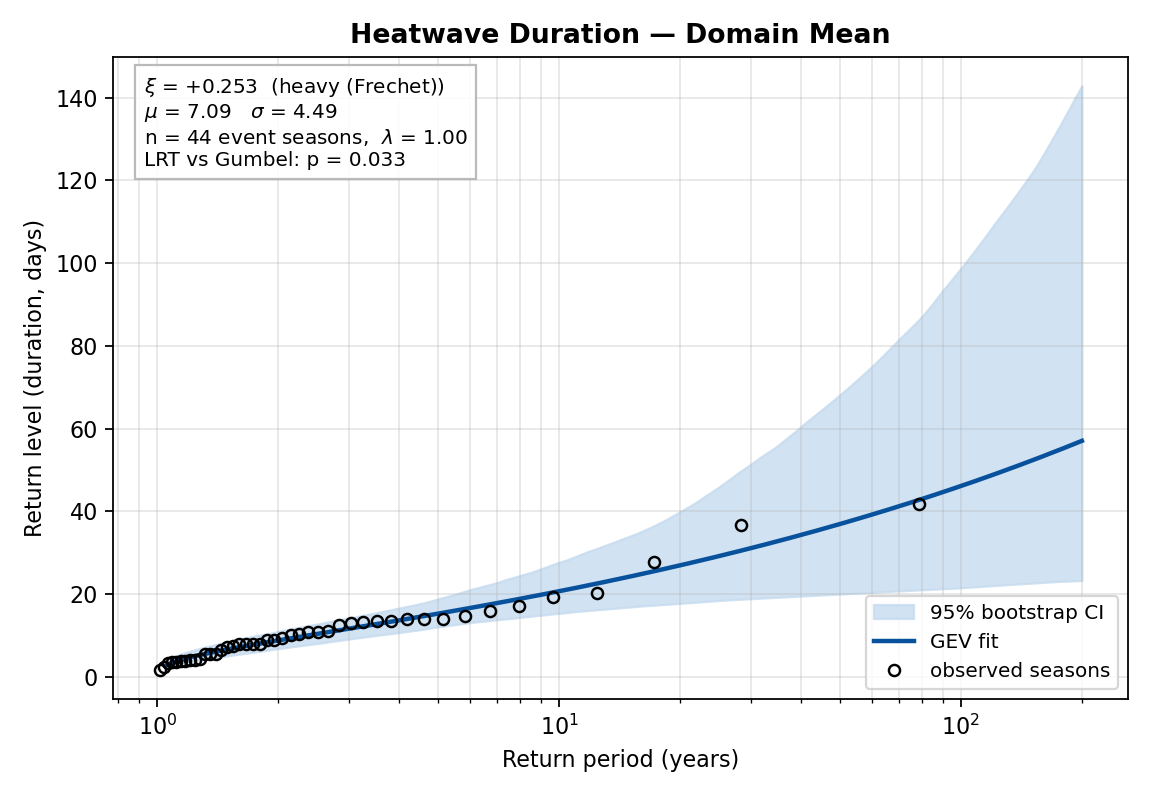

In [23]:
from IPython.display import Image, display

display(
    Image(
        filename=r"C:\Users\franc\heatwave_duration_return_level_curve.png"
    )
)

Years: 44
Min: 1.1360961023740879
Mean: 12.96278059142013
Max: 53.693627424369815


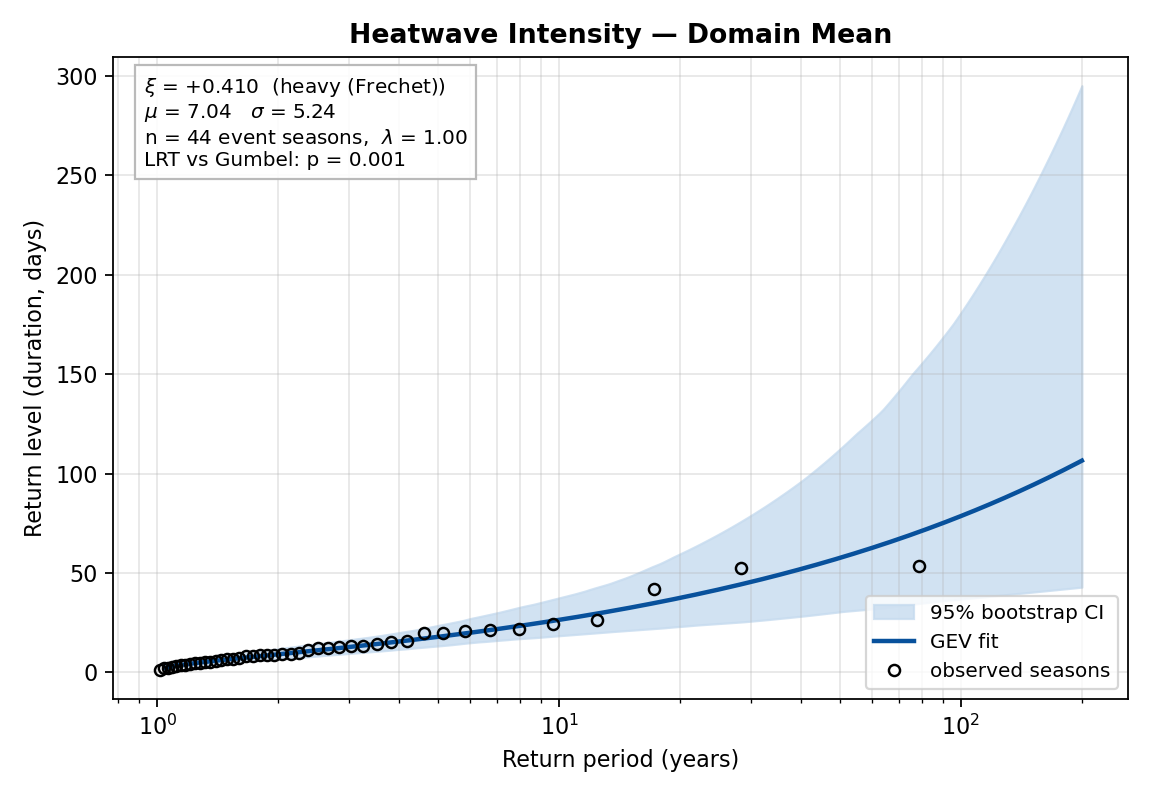

{'mu': np.float64(7.043459517380695), 'sigma': np.float64(5.244258213795818), 'xi': np.float64(0.4102509607218149), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(11.034057260259544), 'lrt_p': np.float64(0.0008945315468081342)}


In [24]:
from IPython.display import Image, display

hw_intensity = hw["hw_intensity"]

# Same --reduce mean idea used in supervisor's code
hw_intensity_mean = hw_intensity.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_intensity_mean.harvest_year.size)
print("Min:", float(hw_intensity_mean.min()))
print("Mean:", float(hw_intensity_mean.mean()))
print("Max:", float(hw_intensity_mean.max()))

fig, stats_hw_intensity = plot_return_level(
    hw_intensity_mean.values,
    title="Heatwave Intensity — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\heatwave_intensity_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\heatwave_intensity_return_level_curve.png"
    )
)

print(stats_hw_intensity)

Years: 44
Min: 0.4559432288586635
Mean: 2.4404691504041005
Max: 7.50956041789868


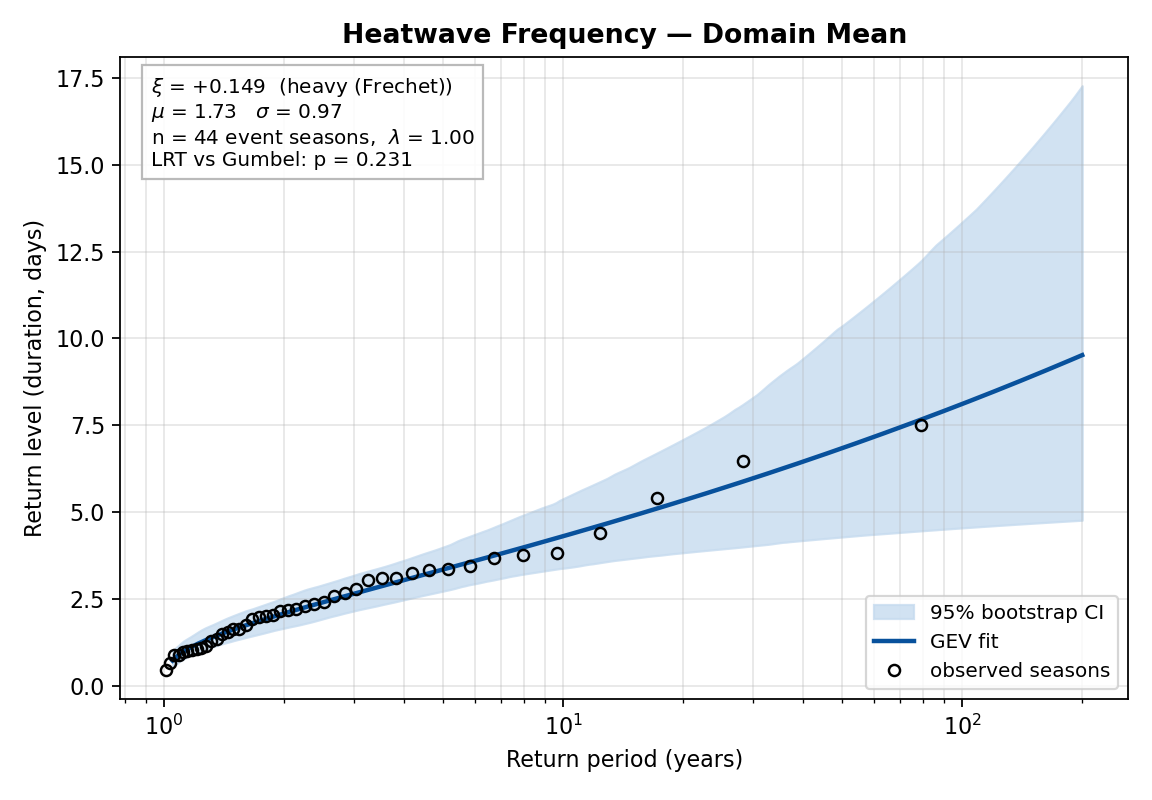

{'mu': np.float64(1.725231756945685), 'sigma': np.float64(0.9666261762641951), 'xi': np.float64(0.14904139671150582), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(1.4372522223328303), 'lrt_p': np.float64(0.2305845086360705)}


In [25]:
hw_frequency = hw["hw_frequency"]

hw_frequency_mean = hw_frequency.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_frequency_mean.harvest_year.size)
print("Min:", float(hw_frequency_mean.min()))
print("Mean:", float(hw_frequency_mean.mean()))
print("Max:", float(hw_frequency_mean.max()))

fig, stats_hw_frequency = plot_return_level(
    hw_frequency_mean.values,
    title="Heatwave Frequency — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\heatwave_frequency_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\heatwave_frequency_return_level_curve.png"
    )
)

print(stats_hw_frequency)

In [26]:
import xarray as xr

fd_file = r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"

fd = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

for var in [
    "fd_frequency",
    "fd_total_duration",
    "fd_max_duration",
    "fd_cumulative_intensity",
    "fd_peak_intensity"
]:
    da = fd[var]

    print("\n", var)
    print("dims:", da.dims)
    print("units:", da.attrs.get("units"))
    print("long_name:", da.attrs.get("long_name"))
    print("min:", float(da.min()))
    print("mean:", float(da.mean()))
    print("max:", float(da.max()))


 fd_frequency
dims: ('harvest_year', 'lat', 'lon')
units: None
long_name: Number of distinct flash drought events per maize harvest year
min: 0.0
mean: 0.25775526053572473
max: 5.0

 fd_total_duration
dims: ('harvest_year', 'lat', 'lon')
units: None
long_name: Total number of flash drought event days per maize harvest year
min: 0.0
mean: 22.060247054686126
max: 732.0

 fd_max_duration
dims: ('harvest_year', 'lat', 'lon')
units: None
long_name: Maximum duration of a single flash drought event
min: 0.0
mean: 21.426496102221442
max: 732.0

 fd_cumulative_intensity
dims: ('harvest_year', 'lat', 'lon')
units: None
long_name: Cumulative SPEI-3 deficit magnitude during complete flash drought events
min: 0.0
mean: 28.042890548706055
max: 1236.89404296875

 fd_peak_intensity
dims: ('harvest_year', 'lat', 'lon')
units: None
long_name: Lowest SPEI-3 value reached during flash drought events
min: -3.8827288150787354
mean: -1.66885244846344
max: -1.0000029802322388


Years: 44
Min: 1.6965183752417794
Mean: 22.060247054686126
Max: 118.54045776918117


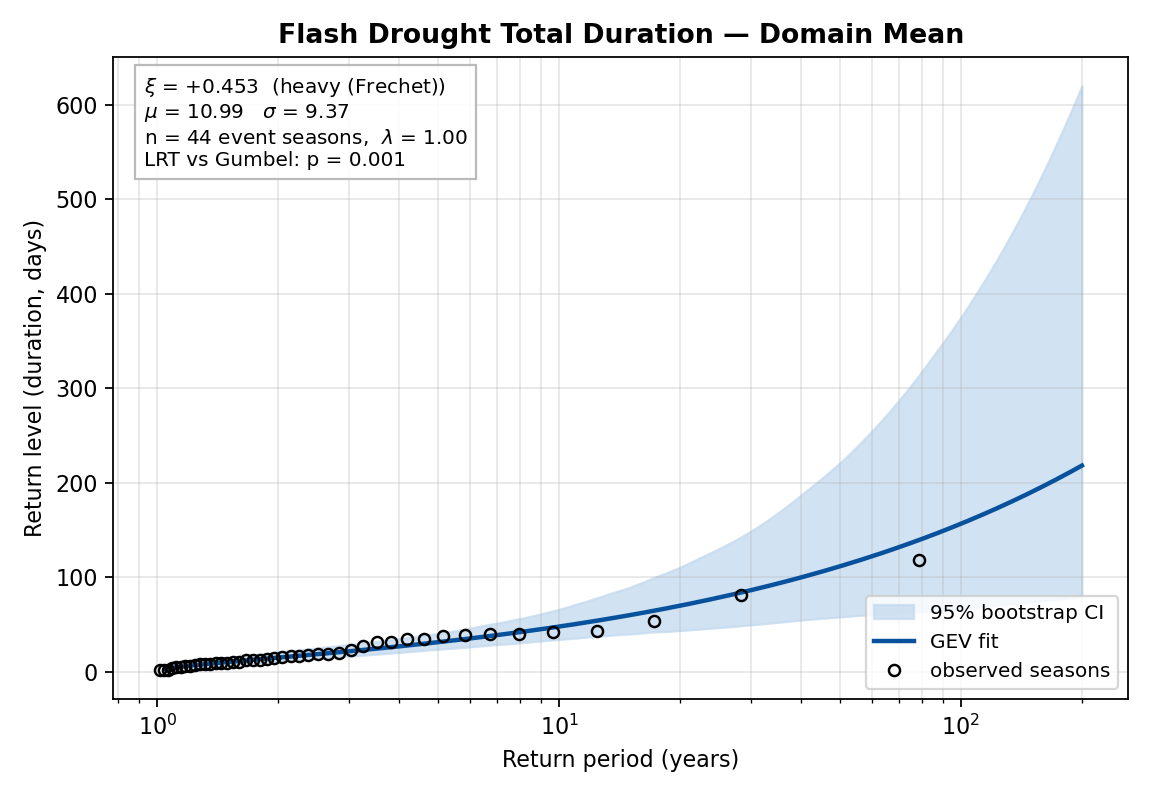

{'mu': np.float64(10.98817379282536), 'sigma': np.float64(9.365823100841862), 'xi': np.float64(0.4530962344236382), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(11.521327891670524), 'lrt_p': np.float64(0.0006880222494361597)}


In [27]:
from IPython.display import Image, display

# ---------------------------------------------------------
# FLASH DROUGHT — TOTAL DURATION
# ---------------------------------------------------------

fd_total_duration = fd["fd_total_duration"]

fd_total_duration_mean = fd_total_duration.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_total_duration_mean.harvest_year.size)
print("Min:", float(fd_total_duration_mean.min()))
print("Mean:", float(fd_total_duration_mean.mean()))
print("Max:", float(fd_total_duration_mean.max()))

fig, stats_fd_total_duration = plot_return_level(
    fd_total_duration_mean.values,
    title="Flash Drought Total Duration — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\flash_drought_total_duration_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\flash_drought_total_duration_return_level_curve.png"
    )
)

print(stats_fd_total_duration)

Years: 44
Min: 1.680689877498388
Mean: 21.426496102221442
Max: 118.15306254029659


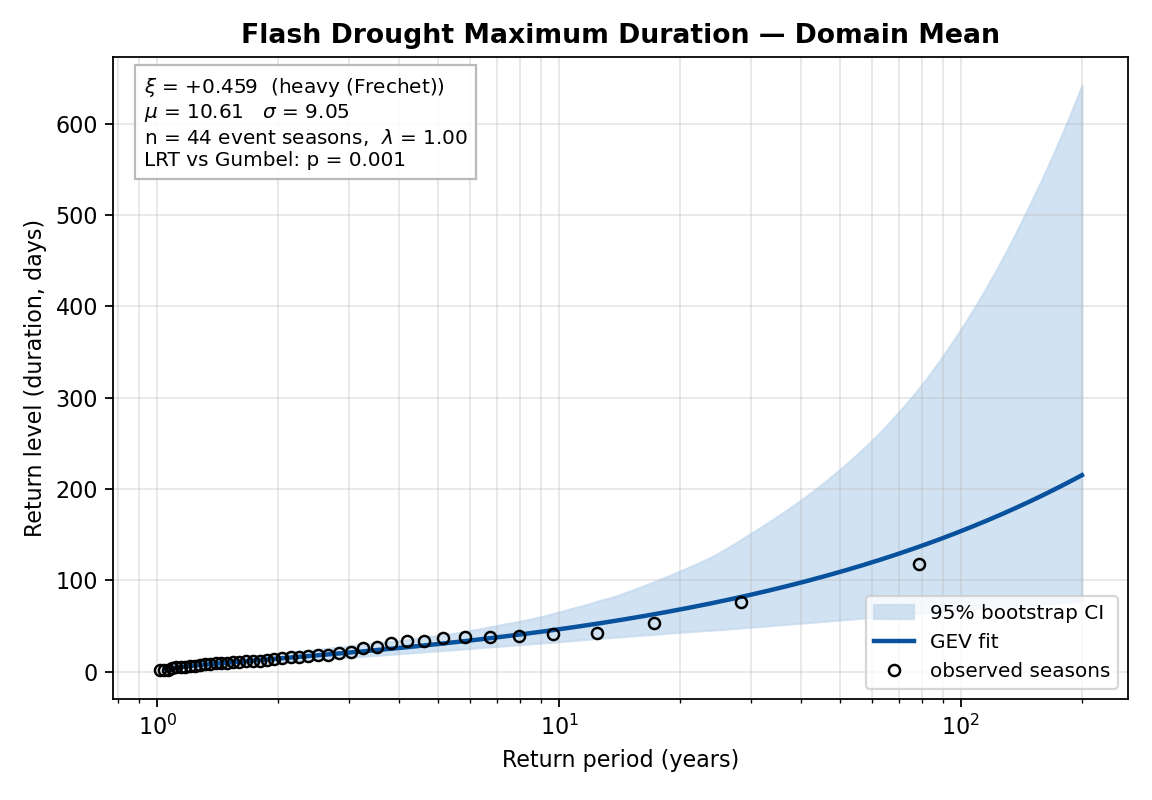

{'mu': np.float64(10.611679678254266), 'sigma': np.float64(9.046799708893744), 'xi': np.float64(0.4591070287343198), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(11.969972352552816), 'lrt_p': np.float64(0.0005406474356362961)}


In [28]:
# ---------------------------------------------------------
# FLASH DROUGHT — MAXIMUM EVENT DURATION
# ---------------------------------------------------------

fd_max_duration = fd["fd_max_duration"]

fd_max_duration_mean = fd_max_duration.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_max_duration_mean.harvest_year.size)
print("Min:", float(fd_max_duration_mean.min()))
print("Mean:", float(fd_max_duration_mean.mean()))
print("Max:", float(fd_max_duration_mean.max()))

fig, stats_fd_max_duration = plot_return_level(
    fd_max_duration_mean.values,
    title="Flash Drought Maximum Duration — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\flash_drought_max_duration_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\flash_drought_max_duration_return_level_curve.png"
    )
)

print(stats_fd_max_duration)

Years: 44
Min: 0.03604126370083817
Mean: 0.25775526053572473
Max: 0.65715667311412


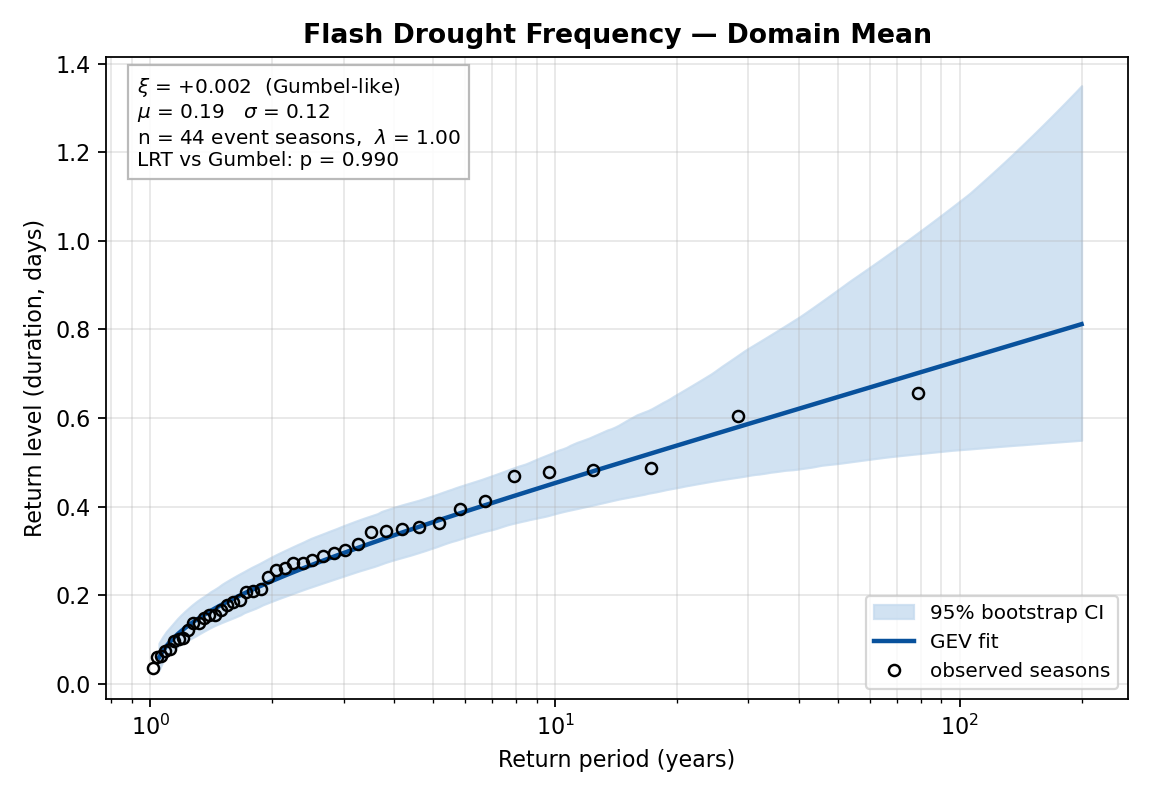

{'mu': np.float64(0.18930380231246013), 'sigma': np.float64(0.11696018492055466), 'xi': np.float64(0.0018619969885507787), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(0.00015904847266767774), 'lrt_p': np.float64(0.9899377917633364)}


In [29]:
# ---------------------------------------------------------
# FLASH DROUGHT — FREQUENCY
# ---------------------------------------------------------

fd_frequency = fd["fd_frequency"]

fd_frequency_mean = fd_frequency.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_frequency_mean.harvest_year.size)
print("Min:", float(fd_frequency_mean.min()))
print("Mean:", float(fd_frequency_mean.mean()))
print("Max:", float(fd_frequency_mean.max()))

fig, stats_fd_frequency = plot_return_level(
    fd_frequency_mean.values,
    title="Flash Drought Frequency — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\flash_drought_frequency_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\flash_drought_frequency_return_level_curve.png"
    )
)

print(stats_fd_frequency)

Years: 44
Min: 1.8405603170394897
Mean: 28.042783737182617
Max: 179.16354370117188


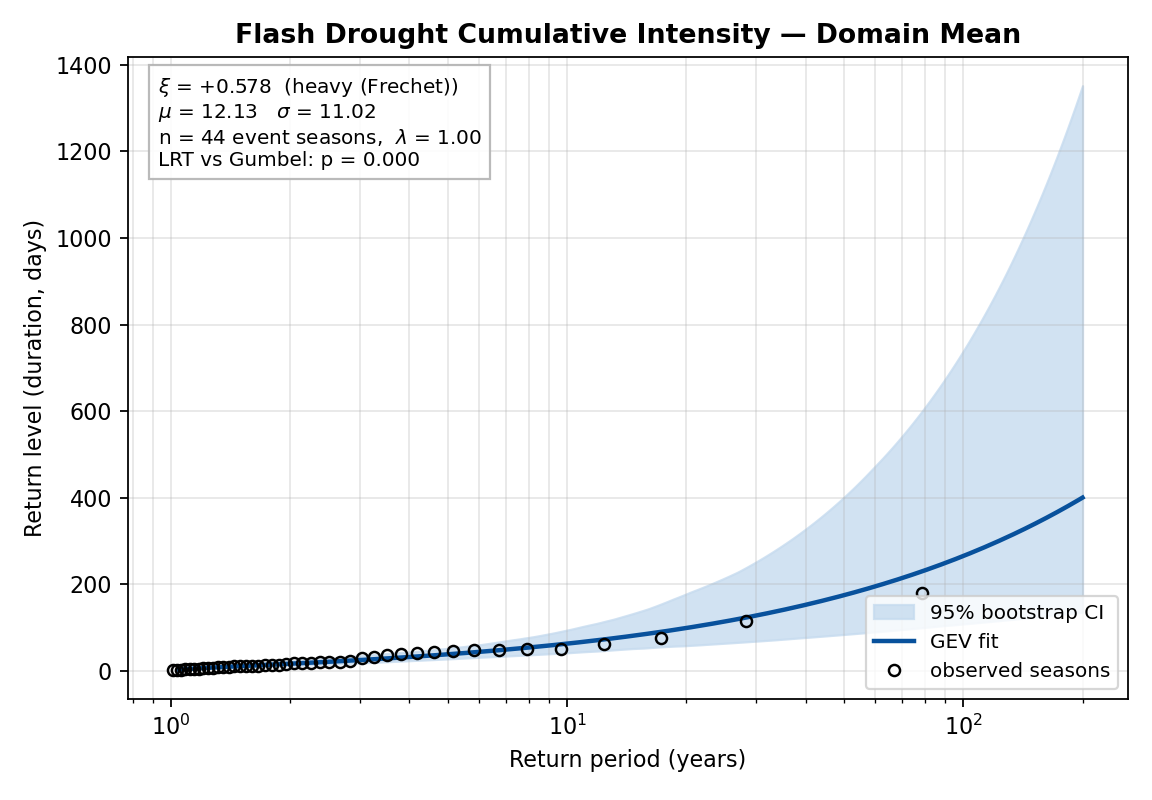

{'mu': np.float64(12.128375418124206), 'sigma': np.float64(11.024436555652306), 'xi': np.float64(0.5780515109840607), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(19.047755982189187), 'lrt_p': np.float64(1.274876007245135e-05)}


In [30]:
# ---------------------------------------------------------
# FLASH DROUGHT — CUMULATIVE INTENSITY
# ---------------------------------------------------------

fd_cumulative_intensity = fd["fd_cumulative_intensity"]

fd_cumulative_intensity_mean = fd_cumulative_intensity.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_cumulative_intensity_mean.harvest_year.size)
print("Min:", float(fd_cumulative_intensity_mean.min()))
print("Mean:", float(fd_cumulative_intensity_mean.mean()))
print("Max:", float(fd_cumulative_intensity_mean.max()))

fig, stats_fd_cumulative_intensity = plot_return_level(
    fd_cumulative_intensity_mean.values,
    title="Flash Drought Cumulative Intensity — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\flash_drought_cumulative_intensity_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\flash_drought_cumulative_intensity_return_level_curve.png"
    )
)

print(stats_fd_cumulative_intensity)

In [31]:
peak = fd["fd_peak_intensity"]

print("dtype:", peak.dtype)
print("NaNs:", int(peak.isnull().sum()))
print("Zeros:", int((peak == 0).sum()))
print("Negative:", int((peak < 0).sum()))

peak_mean = peak.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("\nDomain-mean seasonal series:")
print("Years:", peak_mean.harvest_year.size)
print("Min:", float(peak_mean.min()))
print("Mean:", float(peak_mean.mean()))
print("Max:", float(peak_mean.max()))
print("\nFirst 10 values:")
print(peak_mean.values[:10])

dtype: float32
NaNs: 1043340
Zeros: 0
Negative: 321540

Domain-mean seasonal series:
Years: 44
Min: -2.196134567260742
Mean: -1.5851761102676392
Max: -1.2797218561172485

First 10 values:
[-1.427023  -1.7735571 -1.4218936 -1.4262825 -1.3324742 -1.6359352
 -1.3309329 -1.445133  -1.5100994 -1.5780672]


Years: 44
Min: 1.2797218561172485
Mean: 1.5851761102676392
Max: 2.196134567260742


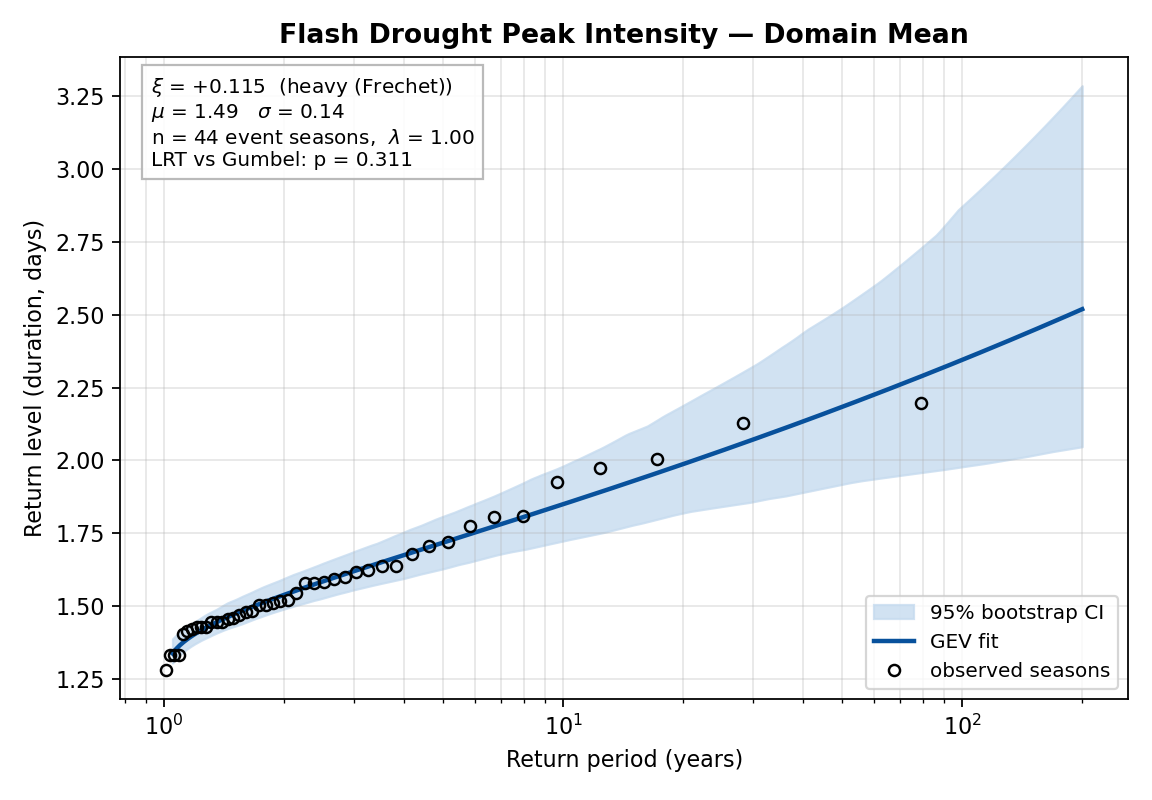

{'mu': np.float64(1.4854022385072274), 'sigma': np.float64(0.14181096950890013), 'xi': np.float64(0.11499856919896329), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(1.025700835443029), 'lrt_p': np.float64(0.311170561103819)}


In [32]:
# ---------------------------------------------------------
# FLASH DROUGHT — PEAK INTENSITY
# Transform negative SPEI-3 so larger = more severe
# ---------------------------------------------------------

fd_peak_intensity = fd["fd_peak_intensity"]

# Spatial mean of event pixels for each harvest year
fd_peak_intensity_mean = fd_peak_intensity.mean(
    dim=["lat", "lon"],
    skipna=True
)

# Reverse sign so larger values represent greater drought severity
fd_peak_severity_mean = -fd_peak_intensity_mean

print("Years:", fd_peak_severity_mean.harvest_year.size)
print("Min:", float(fd_peak_severity_mean.min()))
print("Mean:", float(fd_peak_severity_mean.mean()))
print("Max:", float(fd_peak_severity_mean.max()))

fig, stats_fd_peak_intensity = plot_return_level(
    fd_peak_severity_mean.values,
    title="Flash Drought Peak Intensity — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=r"C:\Users\franc\flash_drought_peak_intensity_return_level_curve.png"
)

display(
    Image(
        filename=r"C:\Users\franc\flash_drought_peak_intensity_return_level_curve.png"
    )
)

print(stats_fd_peak_intensity)

Years: 44
Min: 1.1360961023740879
Mean: 12.96278059142013
Max: 53.693627424369815


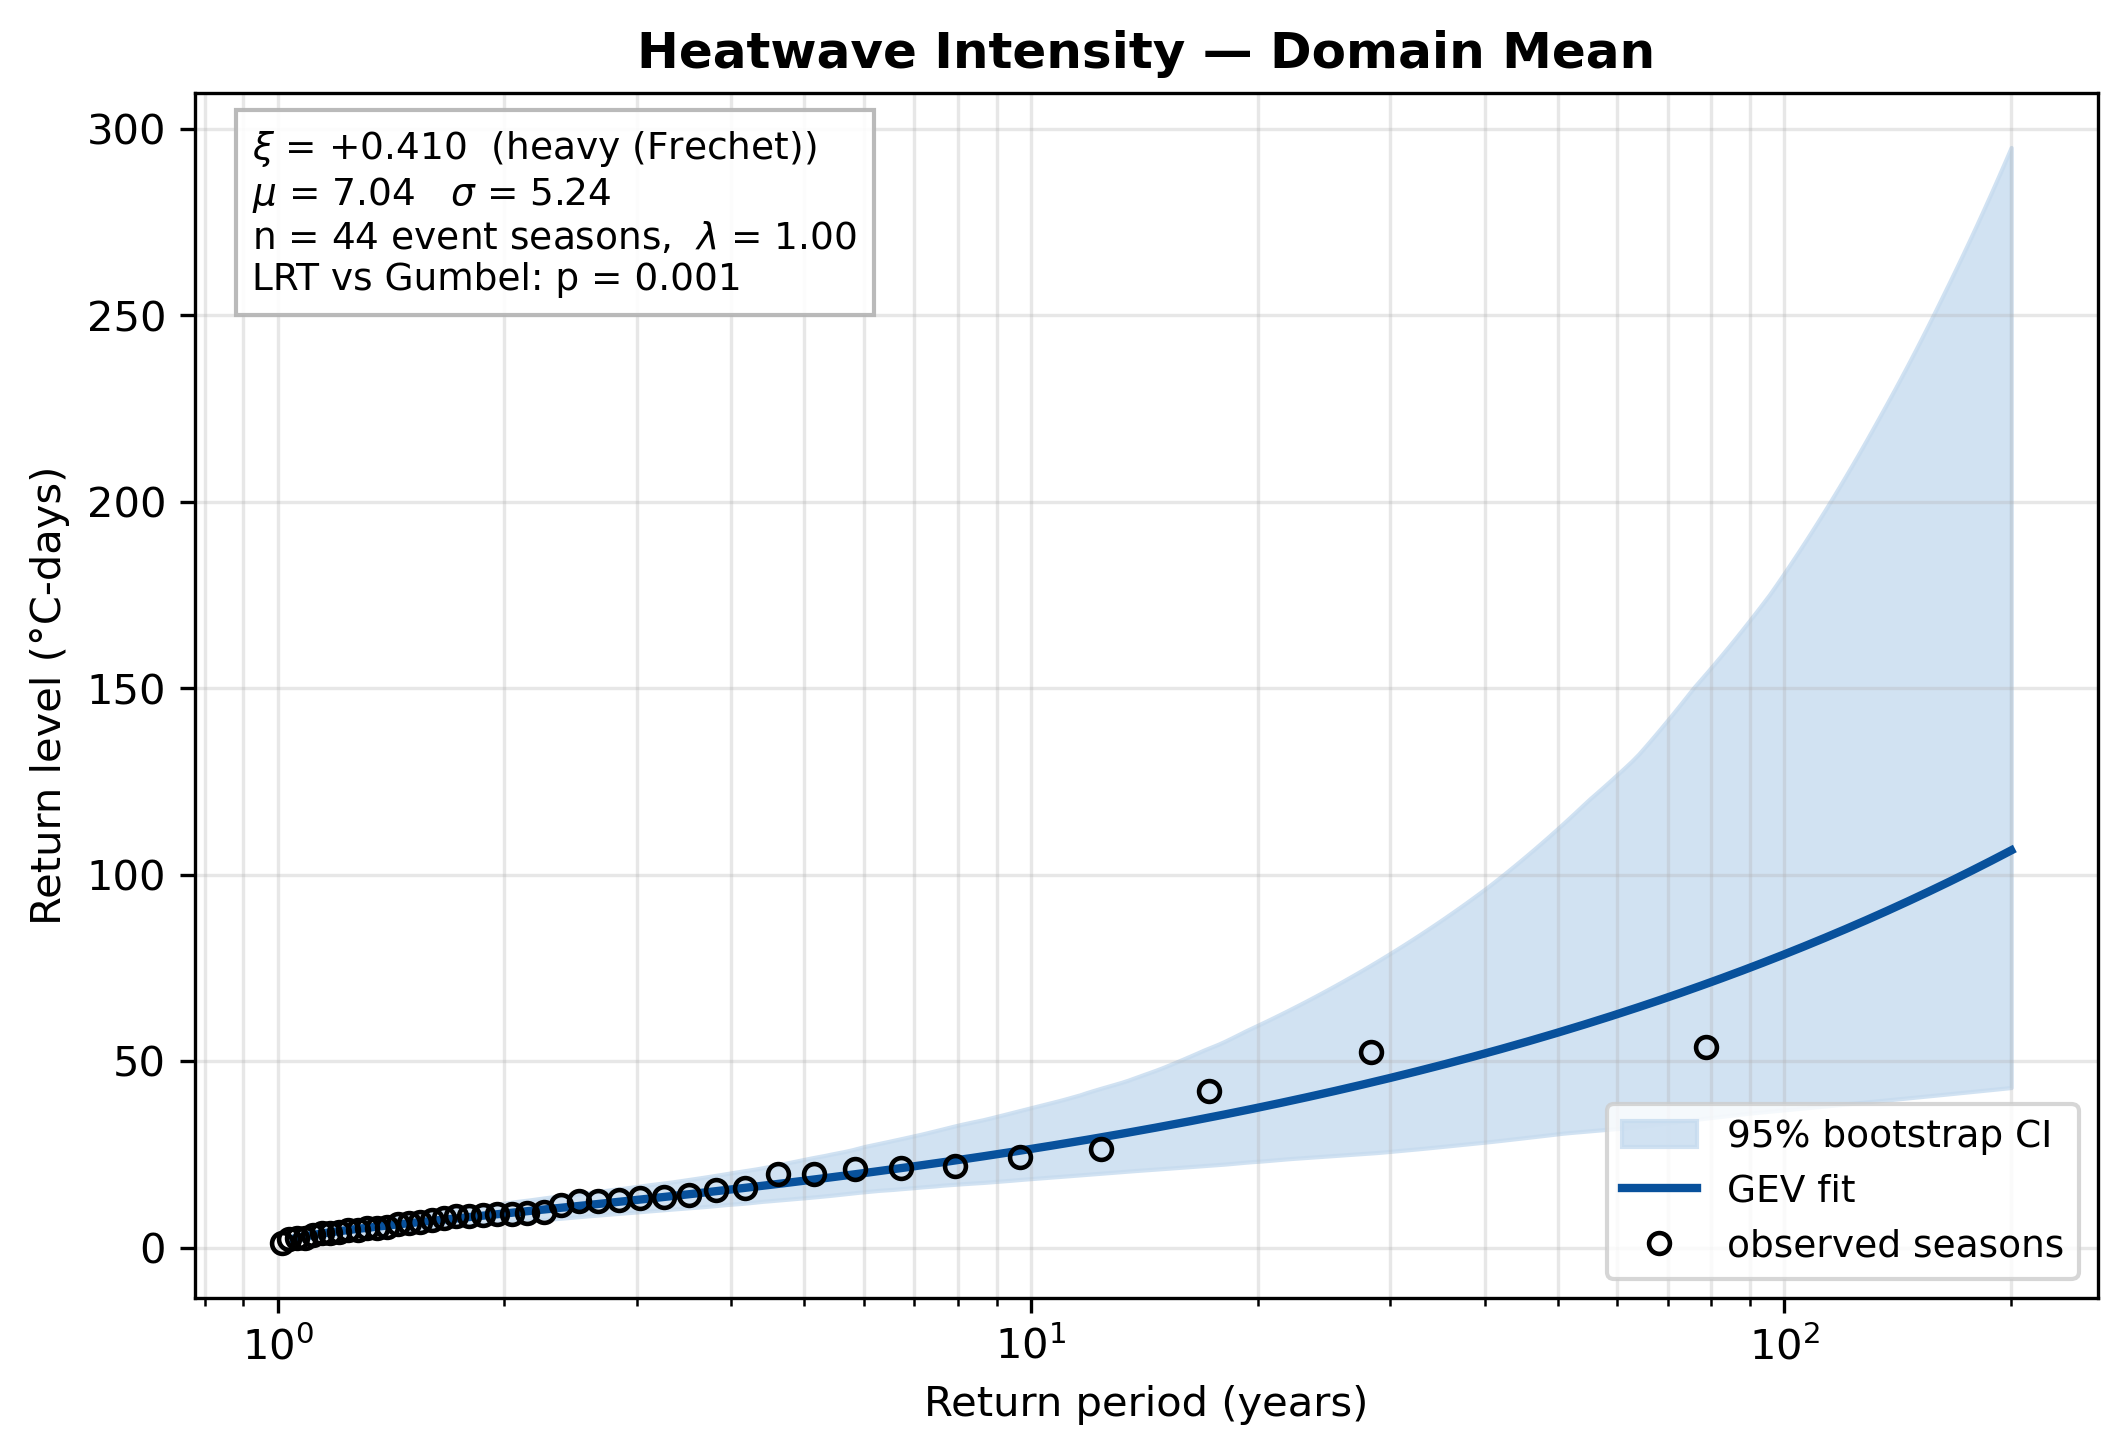

{'mu': np.float64(7.043459517380695), 'sigma': np.float64(5.244258213795818), 'xi': np.float64(0.4102509607218149), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(11.034057260259544), 'lrt_p': np.float64(0.0008945315468081342)}


In [33]:
from IPython.display import Image, display

hw_intensity = hw["hw_intensity"]

# Same --reduce mean idea used in supervisor's code
hw_intensity_mean = hw_intensity.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_intensity_mean.harvest_year.size)
print("Min:", float(hw_intensity_mean.min()))
print("Mean:", float(hw_intensity_mean.mean()))
print("Max:", float(hw_intensity_mean.max()))

fig, stats_hw_intensity = plot_return_level(
    hw_intensity_mean.values,
    title="Heatwave Intensity — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None   # do not save yet
)

# ---------------------------------------------------------
# Correct y-axis label
# ---------------------------------------------------------
ax = fig.axes[0]
ax.set_ylabel("Return level (°C-days)")

# Save AFTER correcting the label
outfile = r"C:\Users\franc\heatwave_intensity_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(Image(filename=outfile))

print(stats_hw_intensity)

Years: 44
Min: 1.8405603170394897
Mean: 28.042783737182617
Max: 179.16354370117188


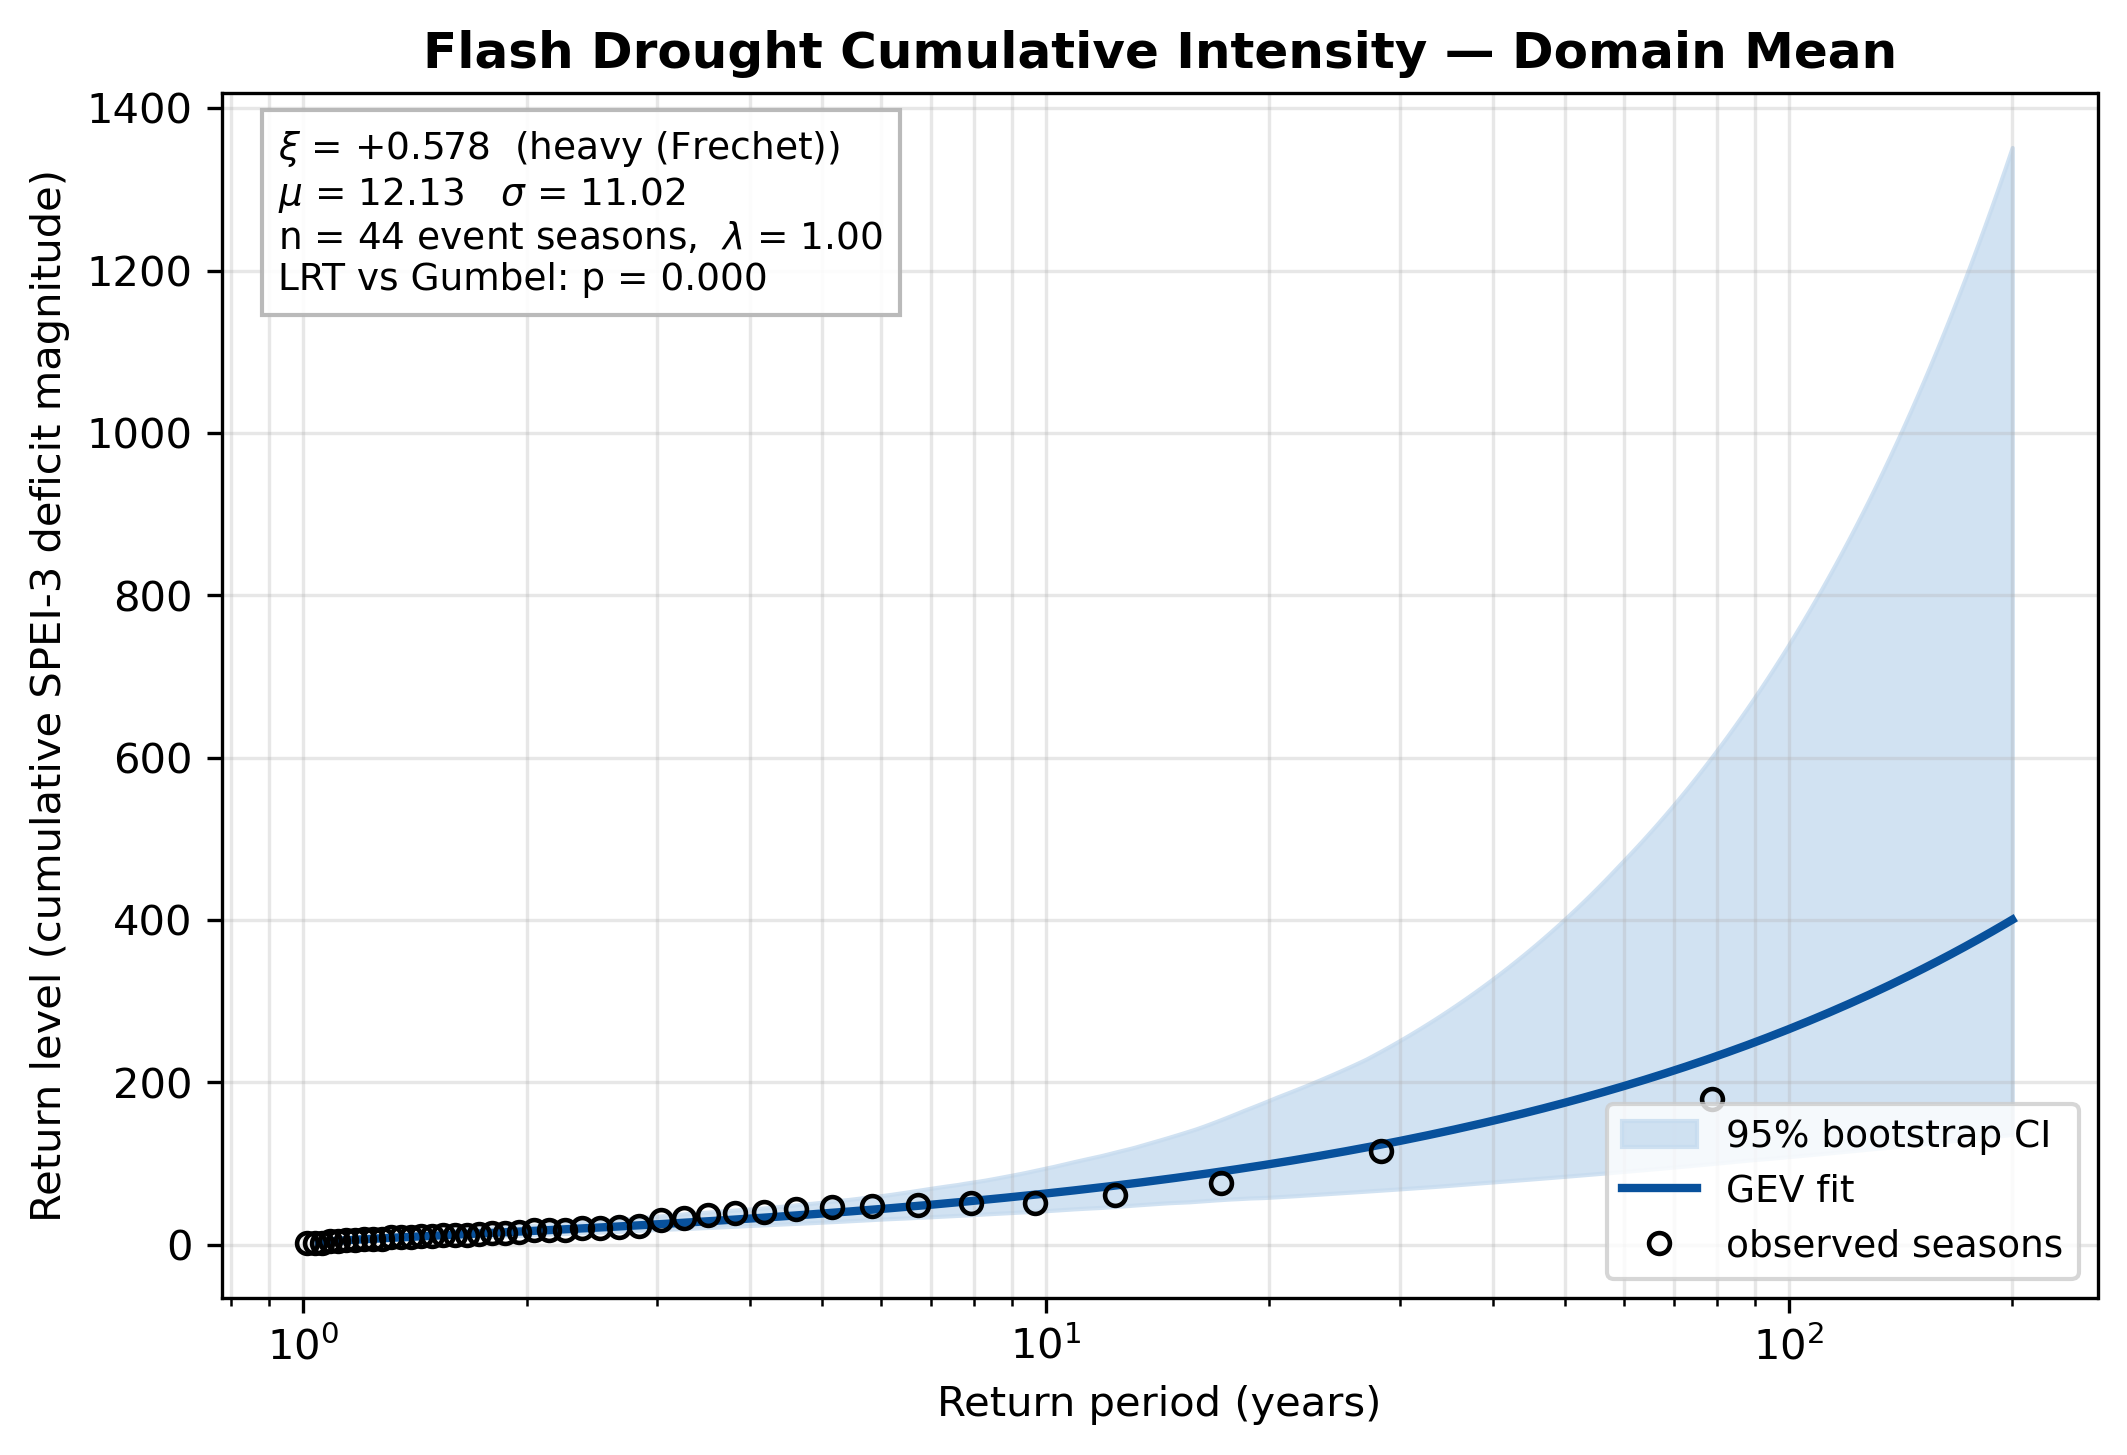

{'mu': np.float64(12.128375418124206), 'sigma': np.float64(11.024436555652306), 'xi': np.float64(0.5780515109840607), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(19.047755982189187), 'lrt_p': np.float64(1.274876007245135e-05)}


In [34]:
# ---------------------------------------------------------
# FLASH DROUGHT — CUMULATIVE INTENSITY
# ---------------------------------------------------------

from IPython.display import Image, display

fd_cumulative_intensity = fd["fd_cumulative_intensity"]

fd_cumulative_intensity_mean = fd_cumulative_intensity.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_cumulative_intensity_mean.harvest_year.size)
print("Min:", float(fd_cumulative_intensity_mean.min()))
print("Mean:", float(fd_cumulative_intensity_mean.mean()))
print("Max:", float(fd_cumulative_intensity_mean.max()))

fig, stats_fd_cumulative_intensity = plot_return_level(
    fd_cumulative_intensity_mean.values,
    title="Flash Drought Cumulative Intensity — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None
)

# Correct y-axis label
ax = fig.axes[0]
ax.set_ylabel(
    "Return level (cumulative SPEI-3 deficit magnitude)"
)

# Save after correcting the label
outfile = r"C:\Users\franc\flash_drought_cumulative_intensity_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(
    Image(
        filename=outfile
    )
)

print(stats_fd_cumulative_intensity)

Years: 44
Min: 0.03604126370083817
Mean: 0.25775526053572473
Max: 0.65715667311412


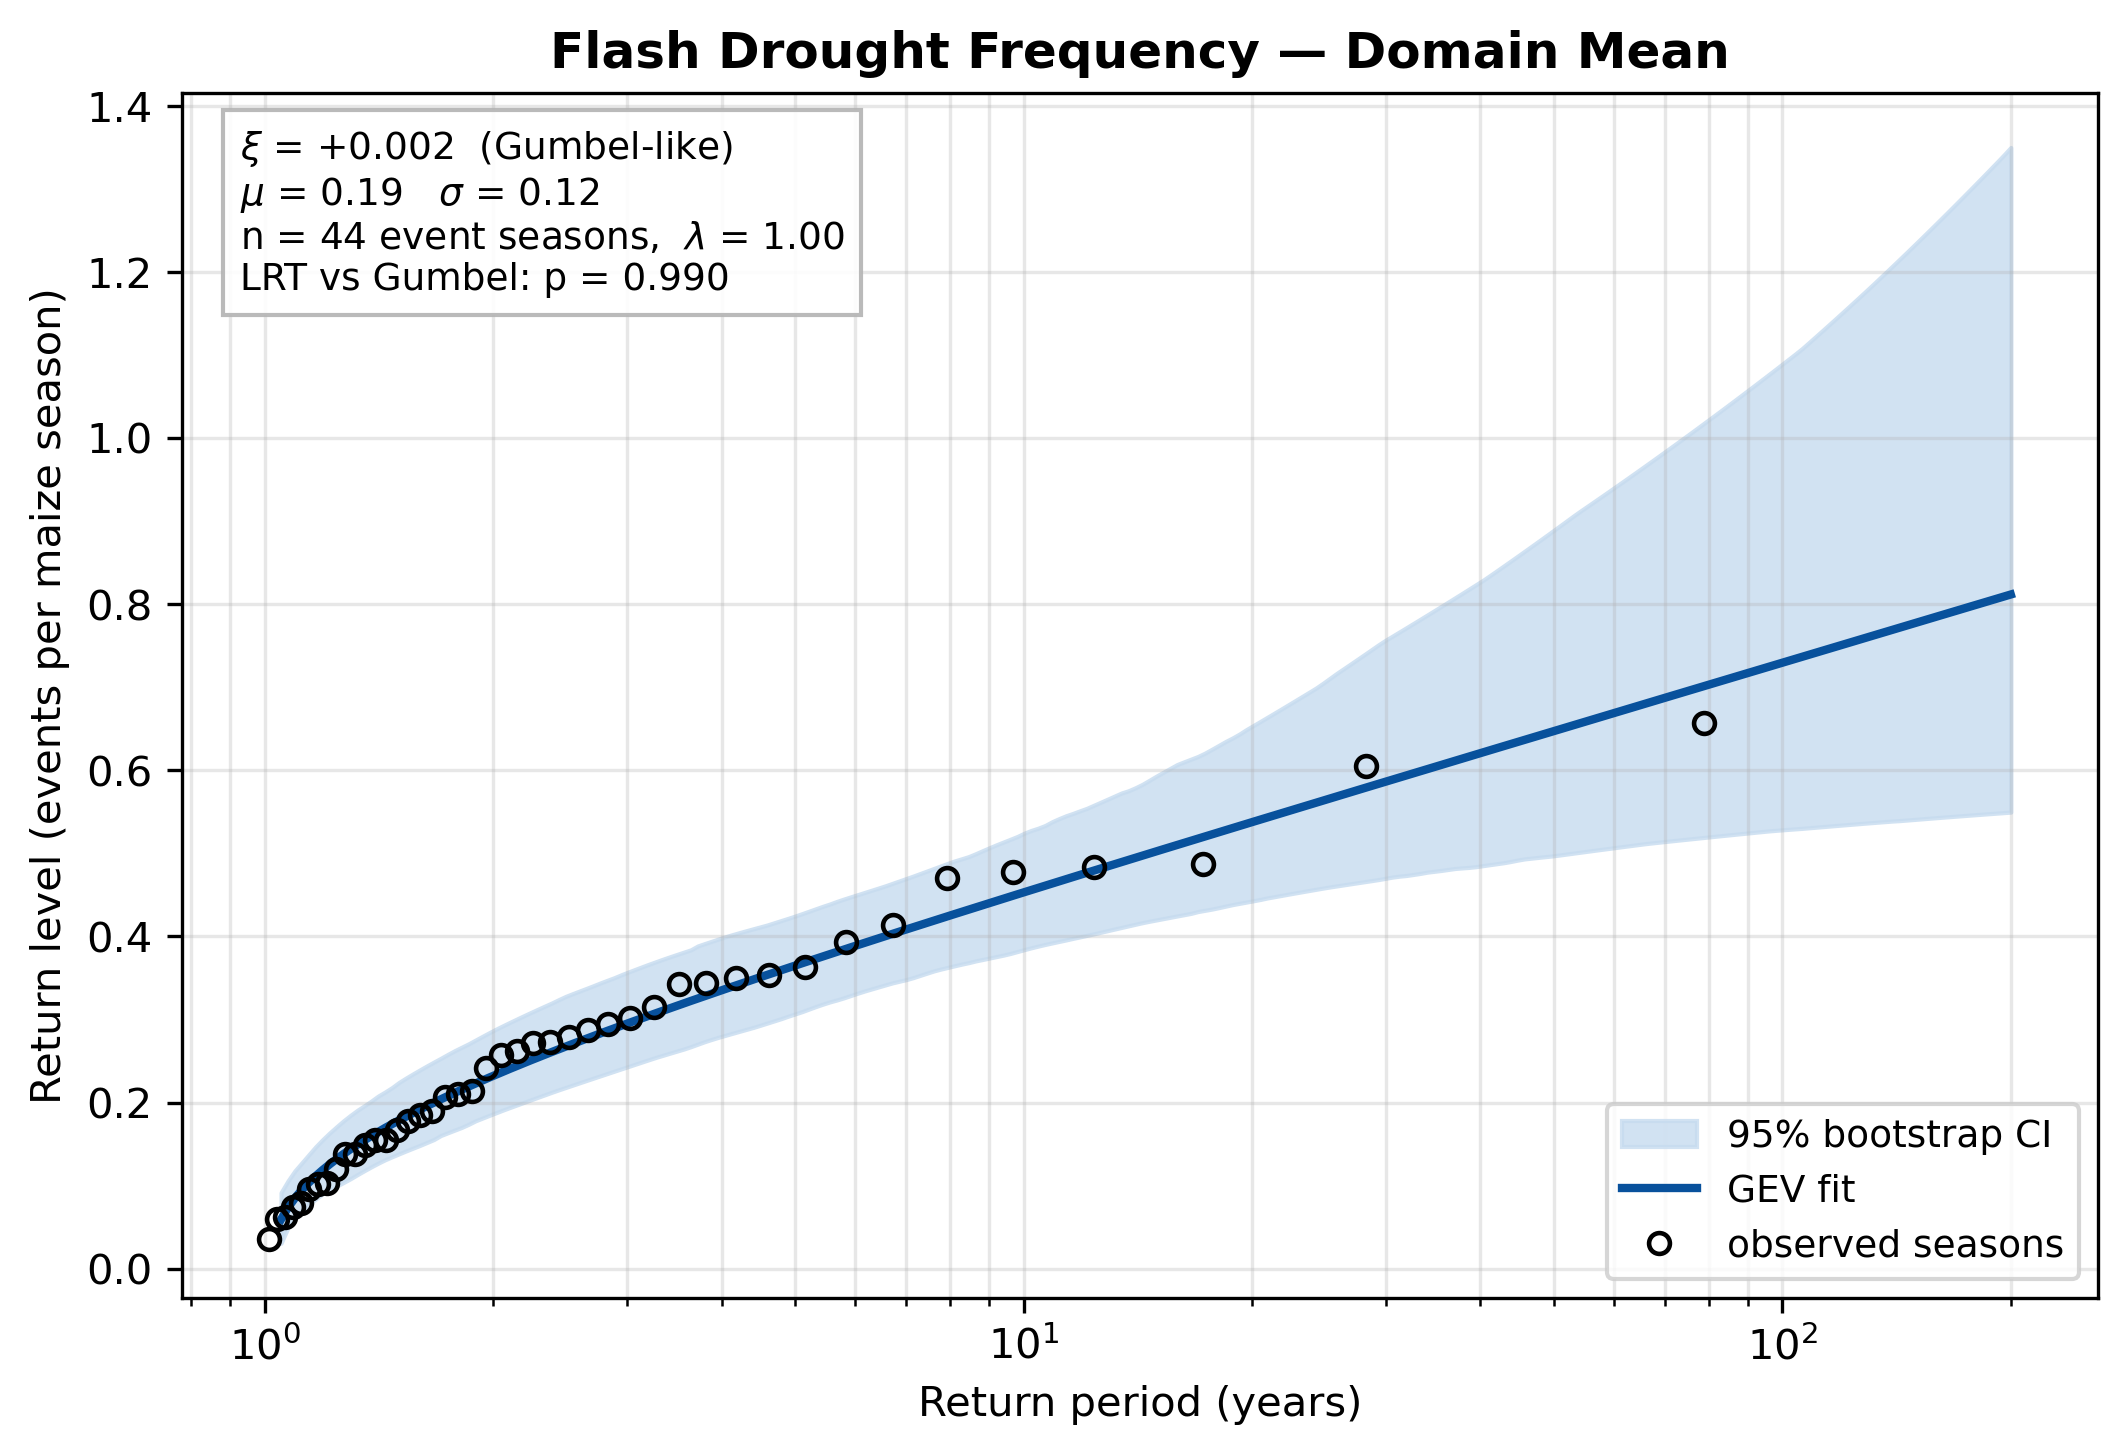

{'mu': np.float64(0.18930380231246013), 'sigma': np.float64(0.11696018492055466), 'xi': np.float64(0.0018619969885507787), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(0.00015904847266767774), 'lrt_p': np.float64(0.9899377917633364)}


In [35]:
# ---------------------------------------------------------
# FLASH DROUGHT — FREQUENCY
# ---------------------------------------------------------

from IPython.display import Image, display

fd_frequency = fd["fd_frequency"]

fd_frequency_mean = fd_frequency.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_frequency_mean.harvest_year.size)
print("Min:", float(fd_frequency_mean.min()))
print("Mean:", float(fd_frequency_mean.mean()))
print("Max:", float(fd_frequency_mean.max()))

fig, stats_fd_frequency = plot_return_level(
    fd_frequency_mean.values,
    title="Flash Drought Frequency — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None
)

# Correct y-axis label
ax = fig.axes[0]
ax.set_ylabel("Return level (events per maize season)")

# Save after correcting the label
outfile = r"C:\Users\franc\flash_drought_frequency_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(
    Image(
        filename=outfile
    )
)

print(stats_fd_frequency)

Years: 44
Min: 1.6077271831263553
Mean: 11.038949518843072
Max: 41.83323477232407


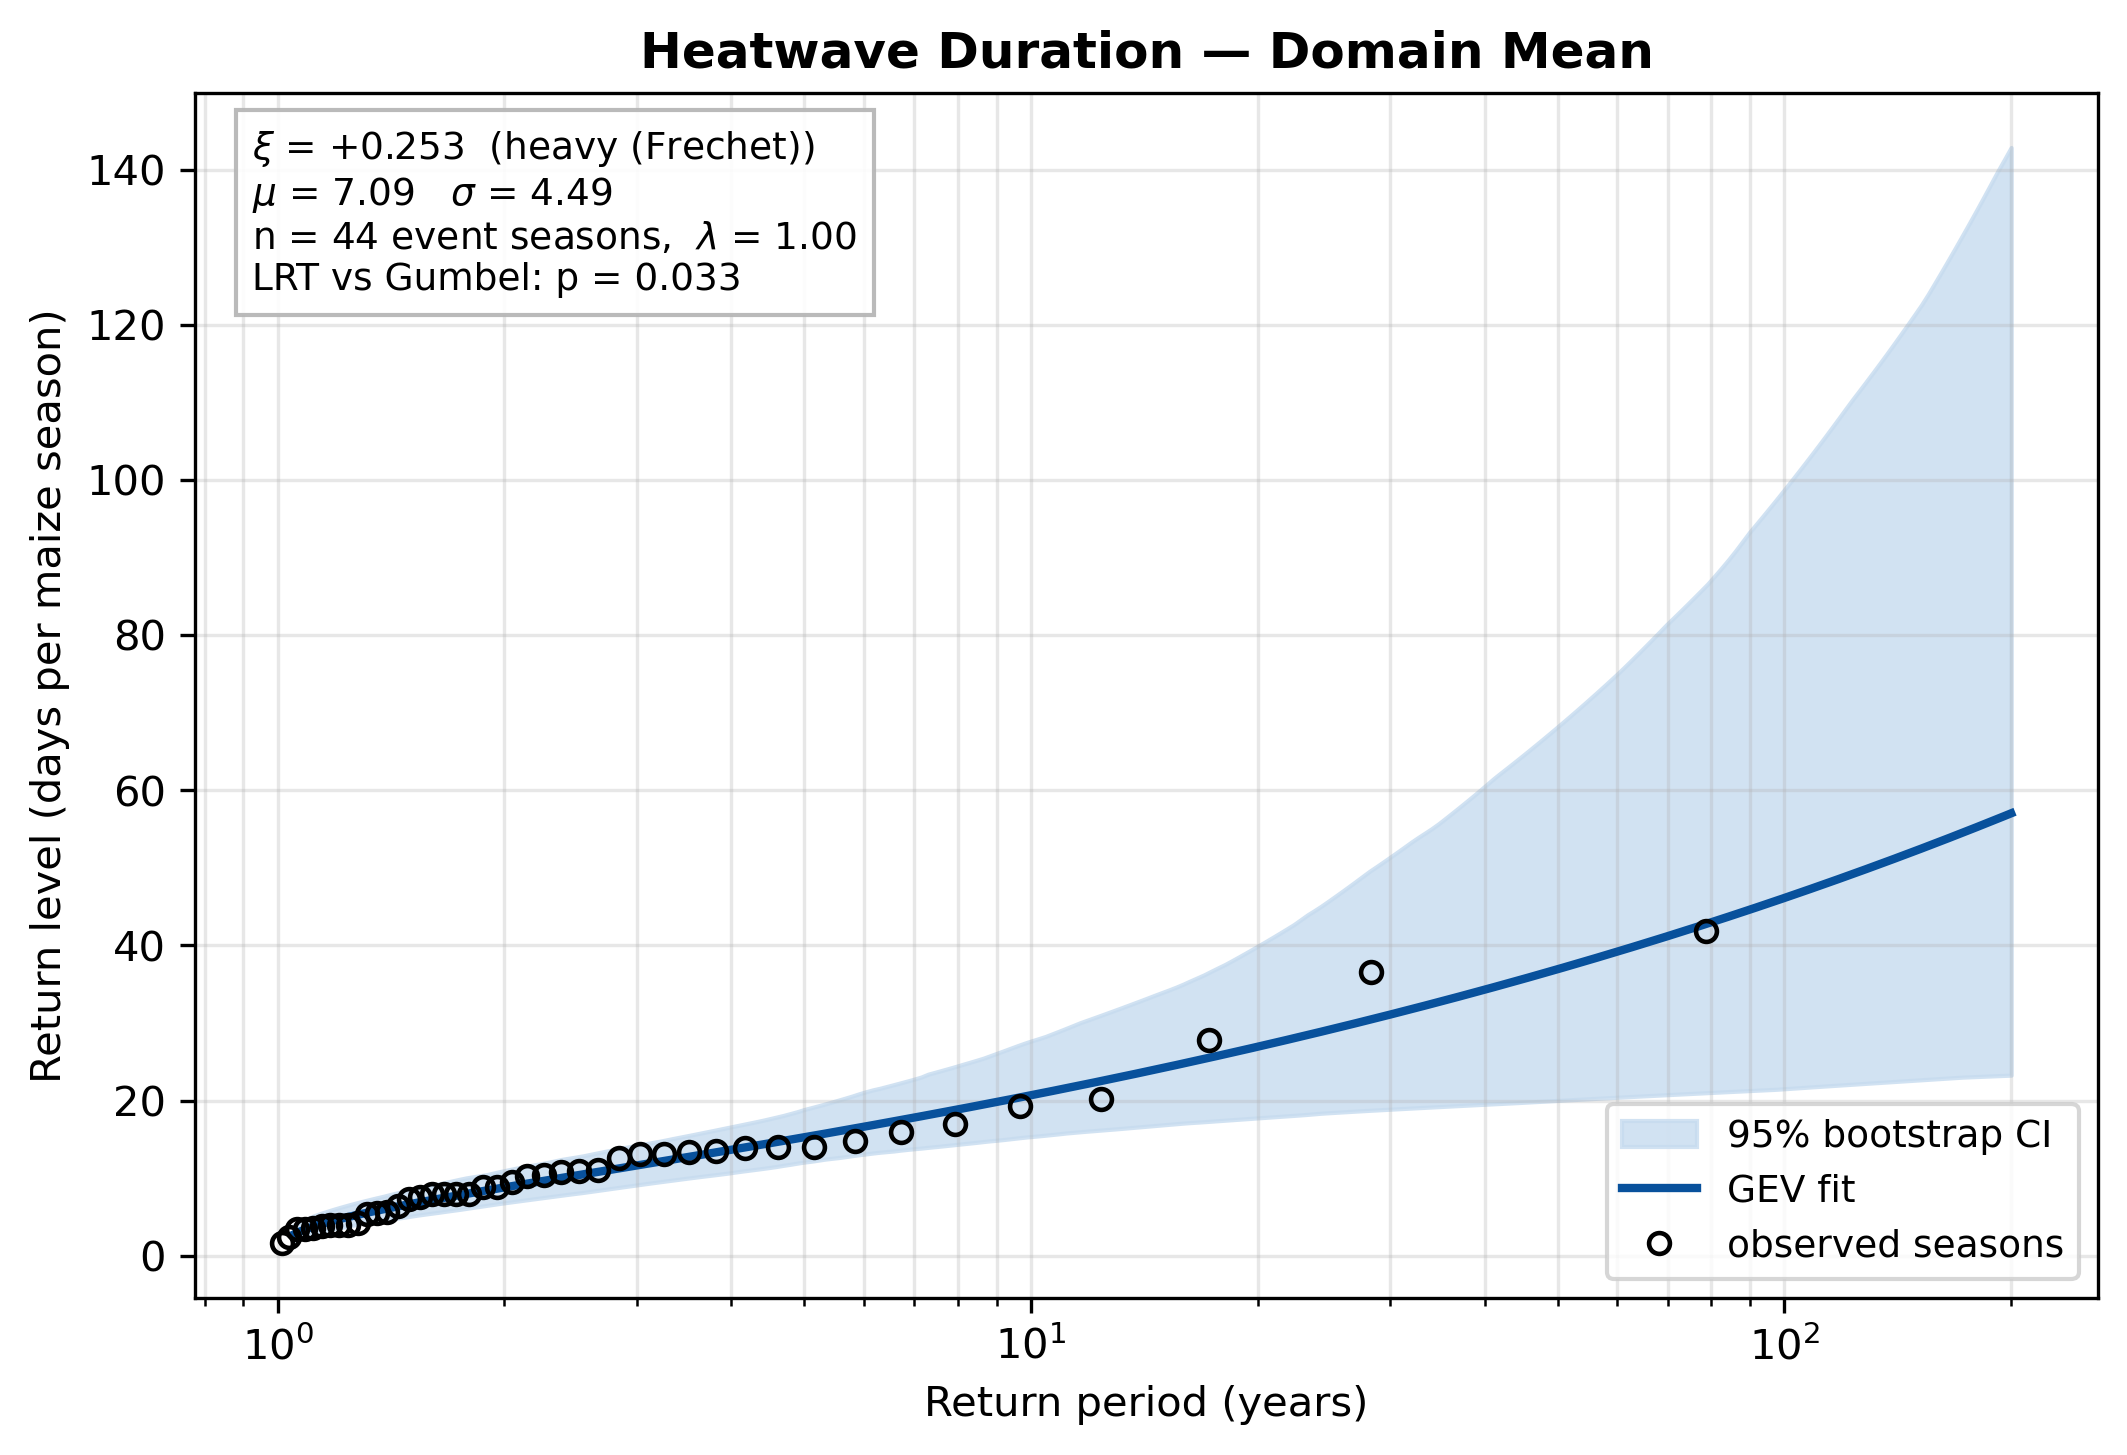

{'mu': np.float64(7.086901194683069), 'sigma': np.float64(4.489504515260911), 'xi': np.float64(0.25262125800621854), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(4.568636956102694), 'lrt_p': np.float64(0.032562464195181114)}


In [36]:
from IPython.display import Image, display

# ---------------------------------------------------------
# HEATWAVE — DURATION
# ---------------------------------------------------------

hw_duration = hw["hw_duration"]

hw_duration_mean = hw_duration.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_duration_mean.harvest_year.size)
print("Min:", float(hw_duration_mean.min()))
print("Mean:", float(hw_duration_mean.mean()))
print("Max:", float(hw_duration_mean.max()))

fig, stats_hw_duration = plot_return_level(
    hw_duration_mean.values,
    title="Heatwave Duration — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None
)

# Correct y-axis label
ax = fig.axes[0]
ax.set_ylabel("Return level (days per maize season)")

# Save after correcting the label
outfile = r"C:\Users\franc\heatwave_duration_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(Image(filename=outfile))

print(stats_hw_duration)

Years: 44
Min: 0.4559432288586635
Mean: 2.4404691504041005
Max: 7.50956041789868


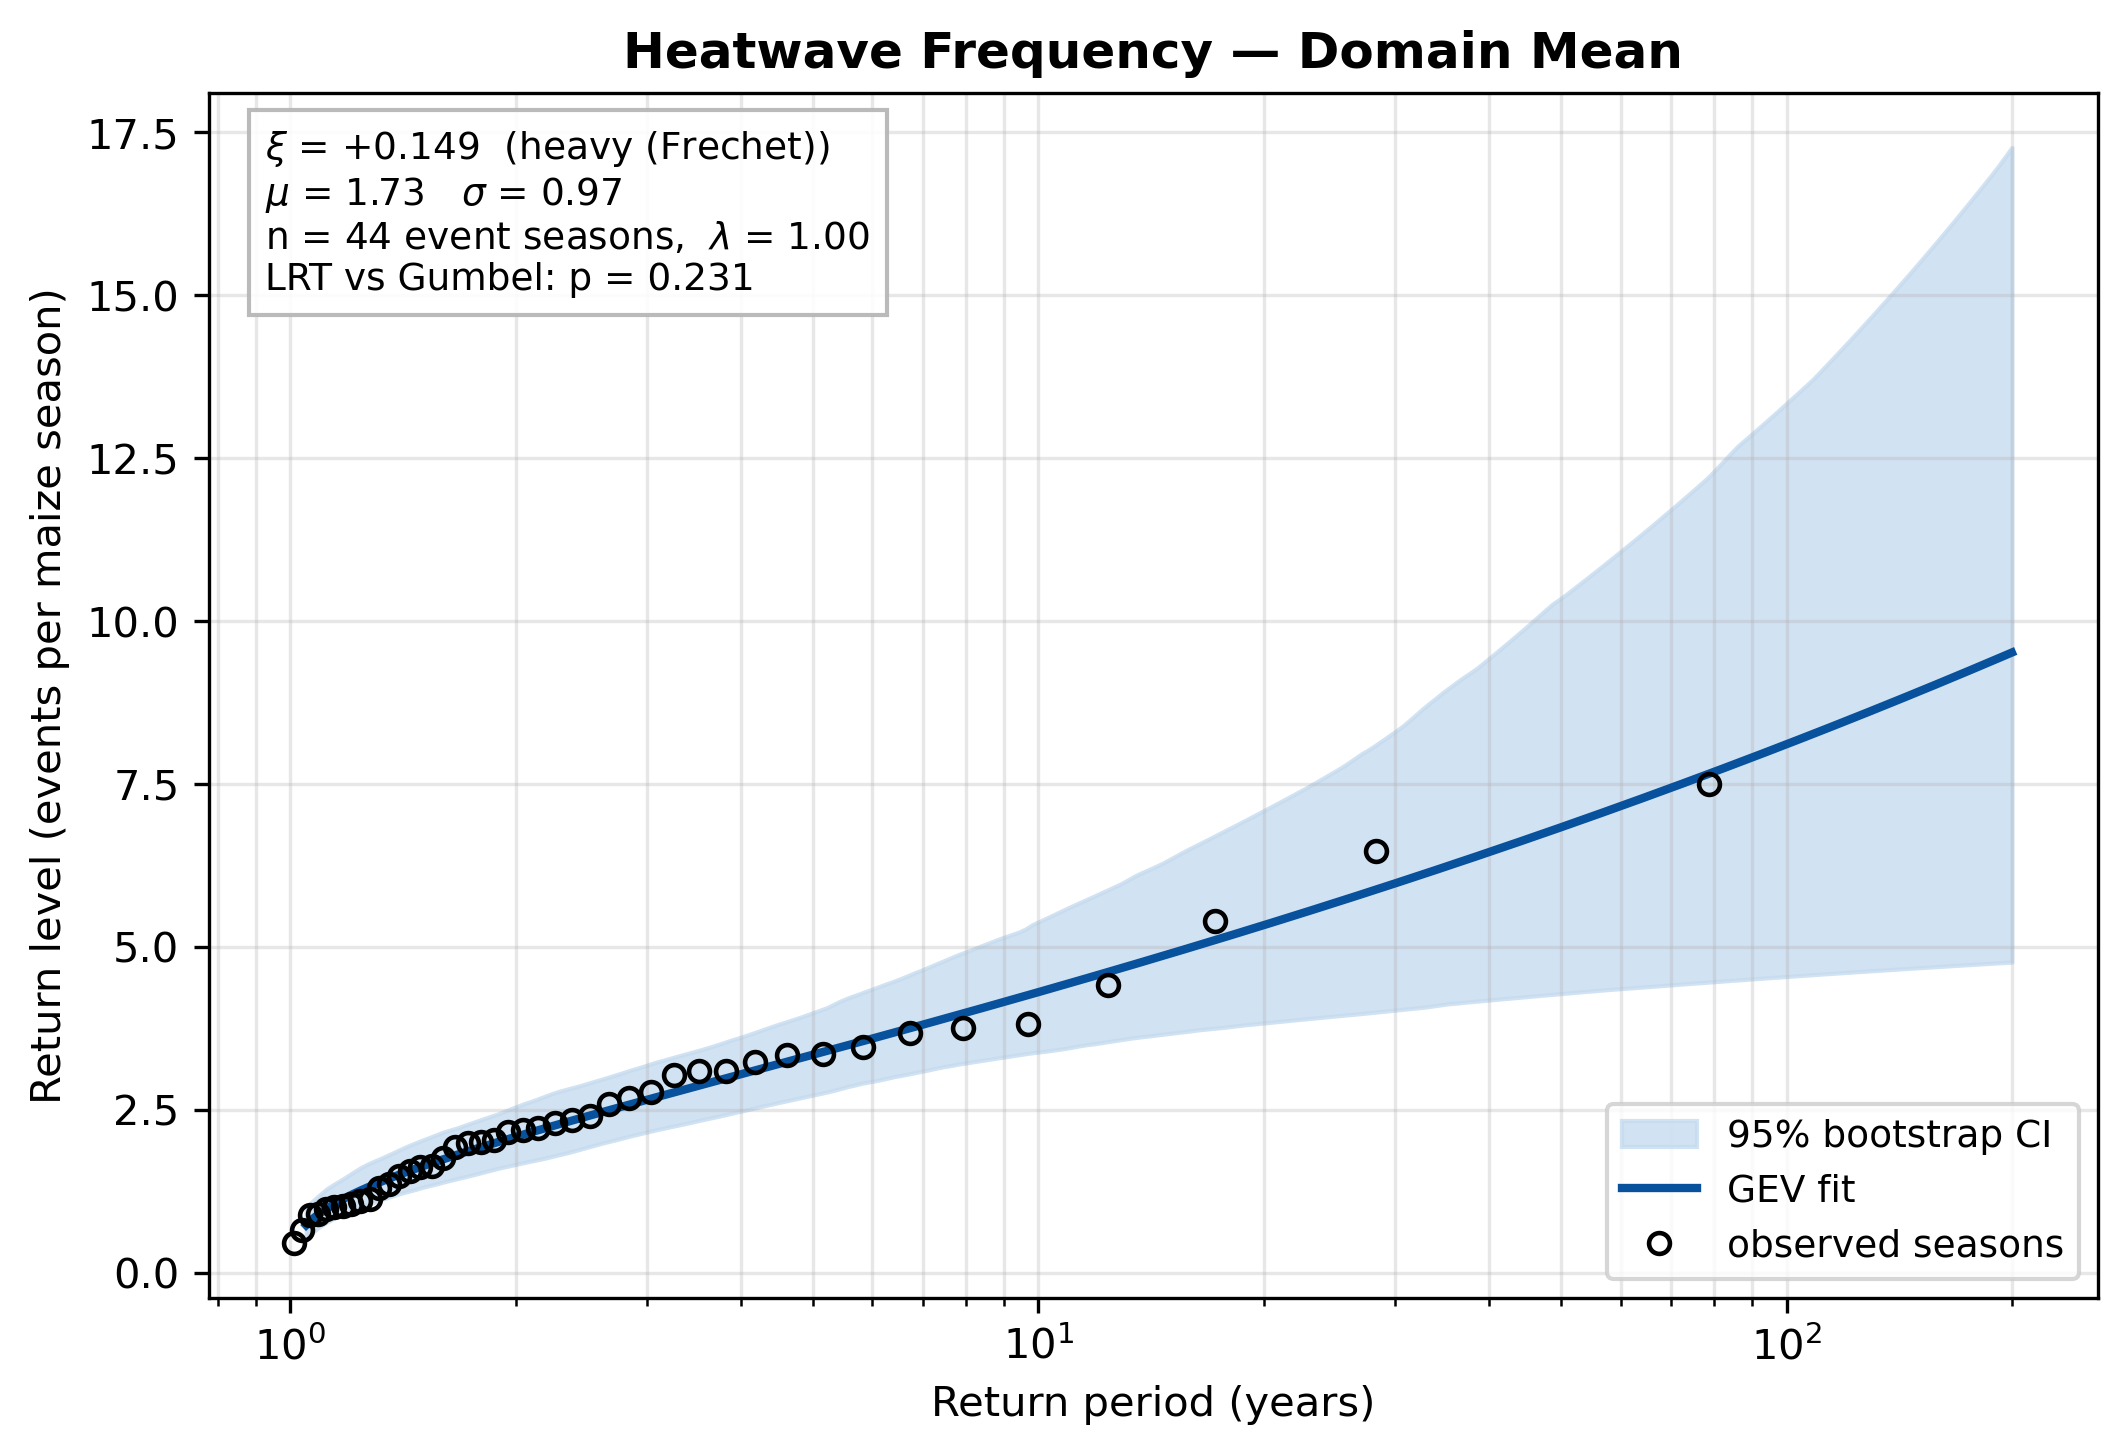

{'mu': np.float64(1.725231756945685), 'sigma': np.float64(0.9666261762641951), 'xi': np.float64(0.14904139671150582), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(1.4372522223328303), 'lrt_p': np.float64(0.2305845086360705)}


In [37]:
from IPython.display import Image, display

# ---------------------------------------------------------
# HEATWAVE — FREQUENCY
# ---------------------------------------------------------

hw_frequency = hw["hw_frequency"]

hw_frequency_mean = hw_frequency.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

print("Years:", hw_frequency_mean.harvest_year.size)
print("Min:", float(hw_frequency_mean.min()))
print("Mean:", float(hw_frequency_mean.mean()))
print("Max:", float(hw_frequency_mean.max()))

fig, stats_hw_frequency = plot_return_level(
    hw_frequency_mean.values,
    title="Heatwave Frequency — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None
)

# Correct y-axis label
fig.axes[0].set_ylabel(
    "Return level (events per maize season)"
)

# Save corrected figure
outfile = r"C:\Users\franc\heatwave_frequency_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(Image(filename=outfile))

print(stats_hw_frequency)

Years: 44
Min: 1.6965183752417794
Mean: 22.060247054686126
Max: 118.54045776918117


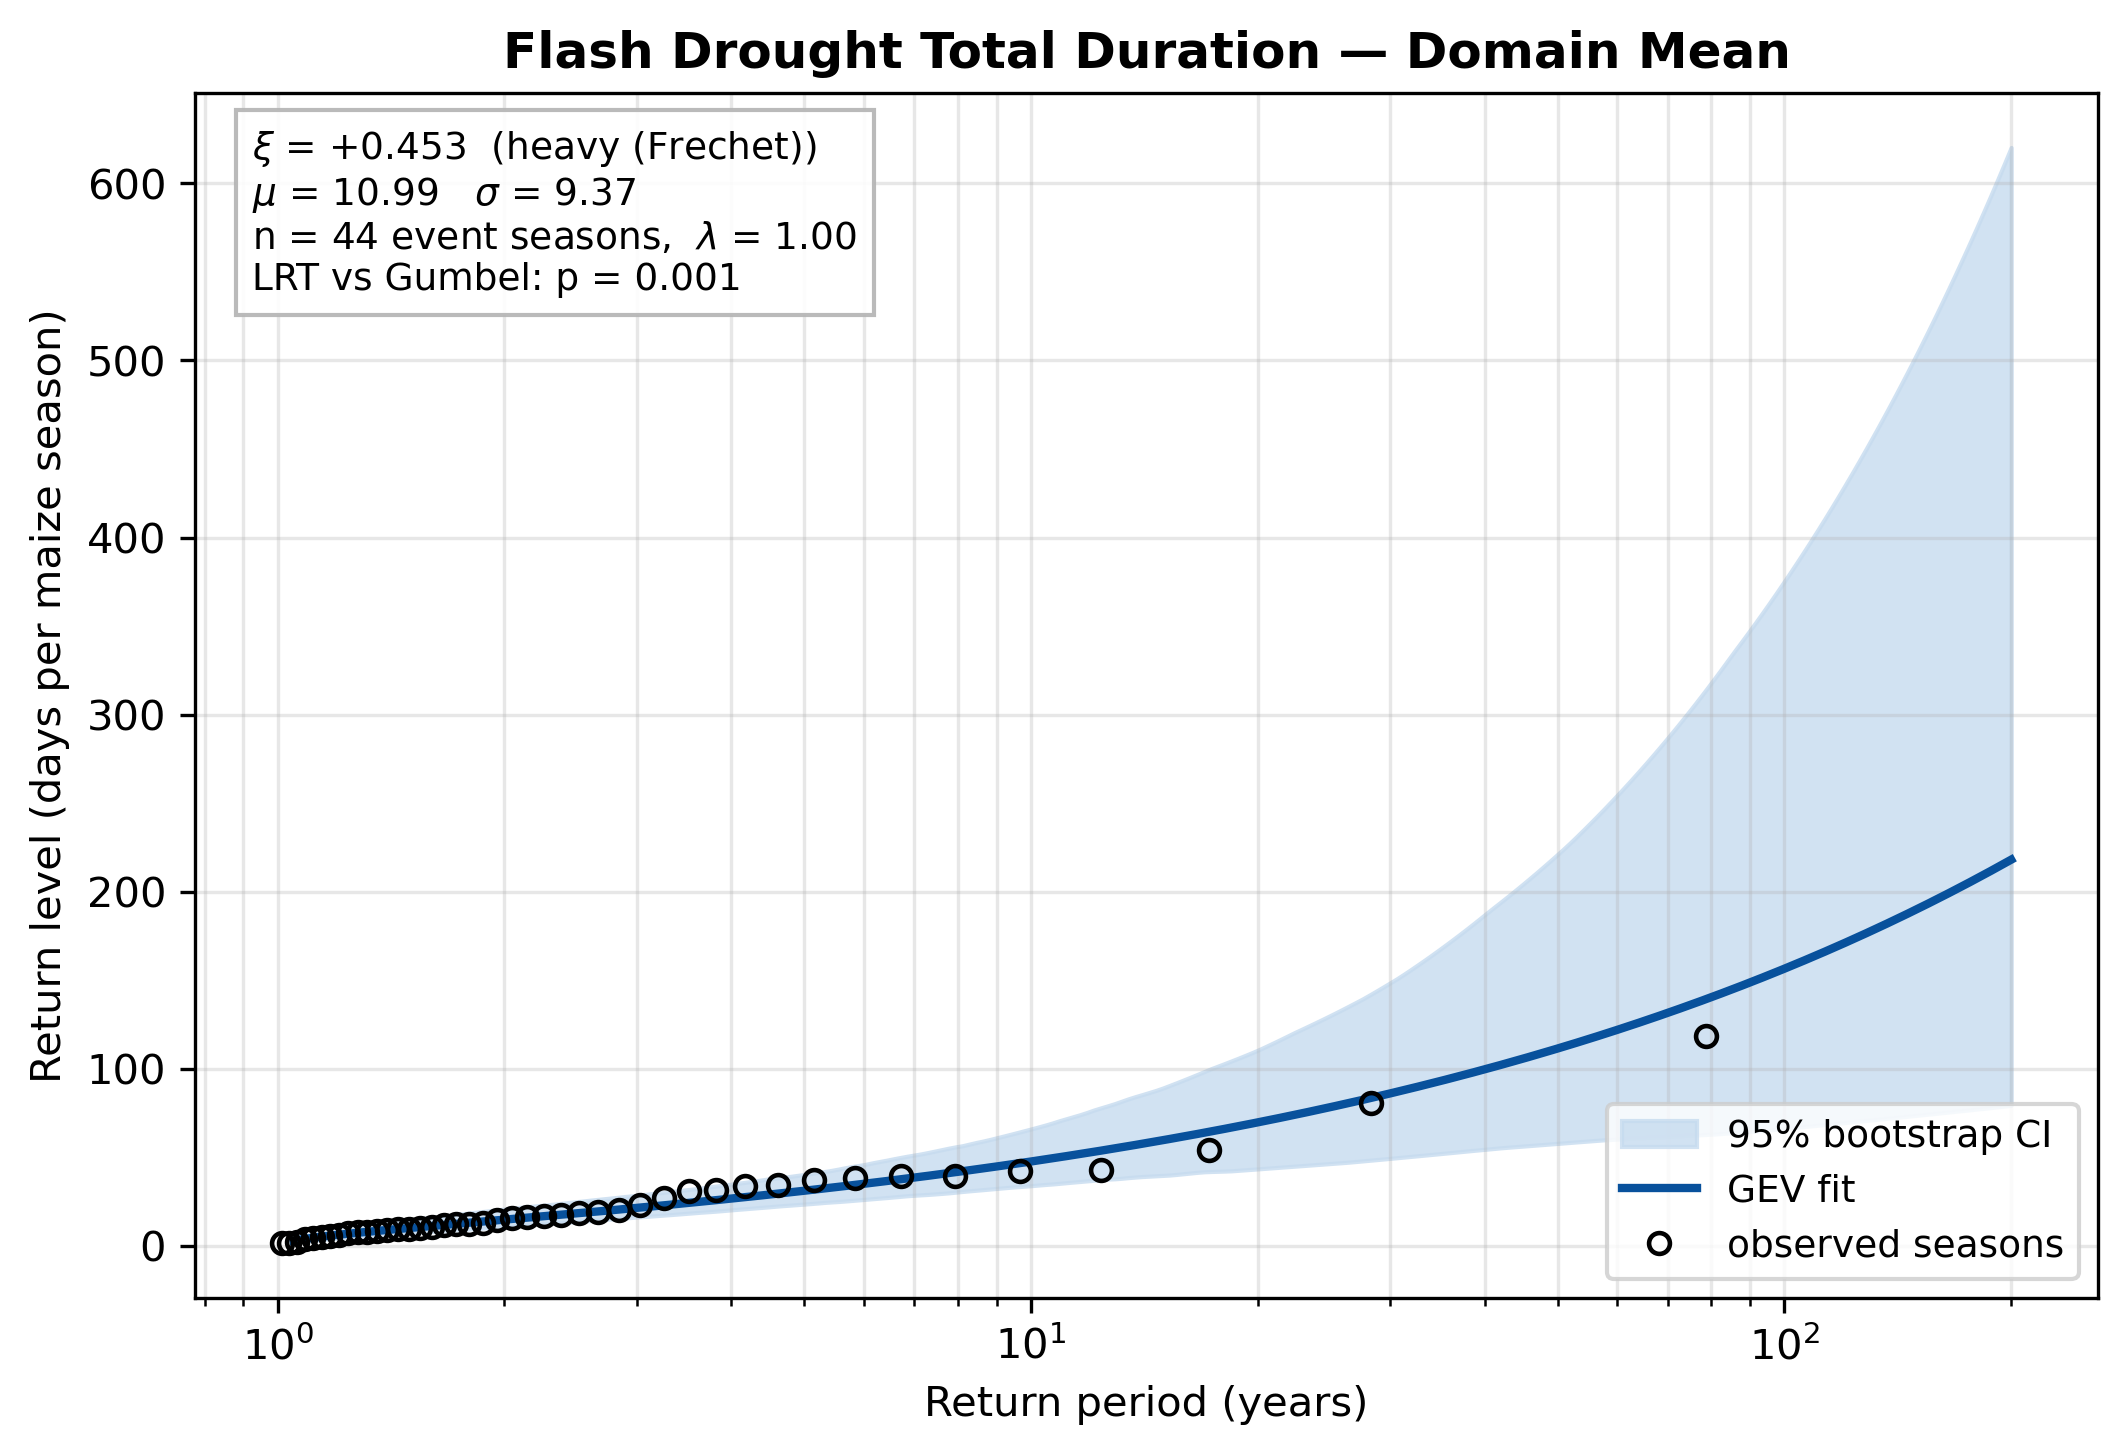

{'mu': np.float64(10.98817379282536), 'sigma': np.float64(9.365823100841862), 'xi': np.float64(0.4530962344236382), 'lam': 1.0, 'n': 44, 'lrt_D': np.float64(11.521327891670524), 'lrt_p': np.float64(0.0006880222494361597)}


In [38]:
from IPython.display import Image, display

# ---------------------------------------------------------
# FLASH DROUGHT — TOTAL DURATION
# ---------------------------------------------------------

fd_total_duration = fd["fd_total_duration"]

fd_total_duration_mean = fd_total_duration.mean(
    dim=["lat", "lon"],
    skipna=True
)

print("Years:", fd_total_duration_mean.harvest_year.size)
print("Min:", float(fd_total_duration_mean.min()))
print("Mean:", float(fd_total_duration_mean.mean()))
print("Max:", float(fd_total_duration_mean.max()))

fig, stats_fd_total_duration = plot_return_level(
    fd_total_duration_mean.values,
    title="Flash Drought Total Duration — Domain Mean",
    include_zeros=False,
    n_boot=500,
    tmax=200,
    outfile=None
)

# Correct y-axis label
fig.axes[0].set_ylabel(
    "Return level (days per maize season)"
)

# Save corrected figure
outfile = r"C:\Users\franc\flash_drought_total_duration_return_level_curve.png"

fig.savefig(
    outfile,
    dpi=300,
    bbox_inches="tight"
)

display(Image(filename=outfile))

print(stats_fd_total_duration)

In [39]:
from PIL import Image
import matplotlib.pyplot as plt

# =========================================================
# 1. COMBINE HEATWAVE RETURN-LEVEL CURVES
# =========================================================

hw_files = [
    r"C:\Users\franc\heatwave_frequency_return_level_curve.png",
    r"C:\Users\franc\heatwave_duration_return_level_curve.png",
    r"C:\Users\franc\heatwave_intensity_return_level_curve.png"
]

hw_images = [Image.open(f) for f in hw_files]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, img in zip(axes, hw_images):
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()

hw_outfile = r"C:\Users\franc\heatwave_return_level_curves_combined.png"

plt.savefig(
    hw_outfile,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", hw_outfile)


# =========================================================
# 2. COMBINE FLASH-DROUGHT RETURN-LEVEL CURVES
# =========================================================

fd_files = [
    r"C:\Users\franc\flash_drought_frequency_return_level_curve.png",
    r"C:\Users\franc\flash_drought_total_duration_return_level_curve.png",
    r"C:\Users\franc\flash_drought_cumulative_intensity_return_level_curve.png"
]

fd_images = [Image.open(f) for f in fd_files]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, img in zip(axes, fd_images):
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()

fd_outfile = r"C:\Users\franc\flash_drought_return_level_curves_combined.png"

plt.savefig(
    fd_outfile,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fd_outfile)

C:\Users\franc\AppData\Local\Temp\ipykernel_34196\3089549920.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Saved: C:\Users\franc\heatwave_return_level_curves_combined.png
Saved: C:\Users\franc\flash_drought_return_level_curves_combined.png


C:\Users\franc\AppData\Local\Temp\ipykernel_34196\3089549920.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [40]:
from PIL import Image

# ---------------------------------------------------------
# MAKE LATEX / OVERLEAF-FRIENDLY COPIES
# ---------------------------------------------------------

files = {
    "heatwave": r"C:\Users\franc\heatwave_return_level_curves_combined.png",
    "flash_drought": r"C:\Users\franc\flash_drought_return_level_curves_combined.png"
}

for name, infile in files.items():

    img = Image.open(infile)

    # Reduce width while preserving aspect ratio
    max_width = 2000

    if img.width > max_width:
        ratio = max_width / img.width
        new_size = (
            max_width,
            int(img.height * ratio)
        )

        img = img.resize(
            new_size,
            Image.Resampling.LANCZOS
        )

    outfile = infile.replace(
        ".png",
        "_OVERLEAF.png"
    )

    img.save(
        outfile,
        format="PNG",
        optimize=True,
        dpi=(150, 150)
    )

    print("Saved:", outfile)
    print("Size:", img.size)

Saved: C:\Users\franc\heatwave_return_level_curves_combined_OVERLEAF.png
Size: (2000, 465)
Saved: C:\Users\franc\flash_drought_return_level_curves_combined_OVERLEAF.png
Size: (2000, 465)
